# Spatially varying fusion of K-SVD and TGV for OCT B-scans

$$X(x) = w(x)\,X_K(x) + \bigl(1 - w(x)\bigr)\,X_T(x), \qquad w(x)\in[0,1]$$

We don't know which weighting function works best, so this notebook implements and compares many of them. The main
target is **structure preservation** (edges, layer boundaries) while keeping noise suppression. Negative results are
reported as they come.

Each section can be run on its own after section 0: it reads its inputs from `cache/` and writes its outputs back.
Set `QUICK_MODE = True` in the config cell (or the environment variable `FUSION_QUICK=1`) for a 3-image smoke run that
stores everything under `cache/quick`, `figures/quick` and `tables/quick`, so it can't overwrite the full results.

Every choice that could change a result is logged in `ASSUMPTIONS.md`.

In [1]:
# ---- configuration ----------------------------------------------------------------------------------------
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # folds run in threads; HGB keeps its own OpenMP threads

QUICK_MODE = False
QUICK_MODE = QUICK_MODE or os.environ.get("FUSION_QUICK") == "1"
FORCE = False                     # True recomputes cached artefacts

SEED = 42
N_WORKERS = 6                     # threads over folds; kept low because the machine has ~16 GB RAM

# Splits inherited from Comparison/comparison.ipynb
TUNE_IDS = [1, 4, 7, 10]                    # tuned K-SVD/TGV parameters: training-only here, never scored
HELD_OUT_IDS = [13, 14, 15, 16, 17]         # unseen by the K-SVD dictionary
OTHER_IDS = [2, 3, 5, 6, 8, 9, 11, 12]      # K-SVD dictionary saw their averaged images
CASES = [13, 15, 16] if QUICK_MODE else sorted(TUNE_IDS + HELD_OUT_IDS + OTHER_IDS)
EVAL_IDS = [13, 15, 16] if QUICK_MODE else sorted(HELD_OUT_IDS + OTHER_IDS)

# Base methods: the frozen settings of Comparison/comparison.ipynb (see Comparison/outputs/run_log.txt)
TGV_PARAMS = {"alpha": 0.2, "beta": 1.0}
KSVD_PARAMS = {"omp_C": 1.6, "lambda_scale": 3.0}

# Masks
ROI_SIGMA, ROI_CLOSE, DROP_COLS = 3.0, 15, 15
EDGE_SIGMA, EDGE_TOP_PCT, EDGE_DILATE = 1.5, 10.0, 2

# Diagnostics
BAND_SIGMAS = (3.0, 10.0)
WINNER_WIN, WINNER_SMOOTH = 15, 7.0

# Features and weighting functions
SCALES = (1, 2, 4)                # feature smoothing scales, selected by inner CV
SAMPLES_PER_CASE = 8000 if QUICK_MODE else 20000
INNER_K = 3
RIDGE_GRID = (0.01, 1.0, 100.0)
HGB_LEAVES = (15, 31)
HGB_SCALE, HGB_WINDOW = 2, 15
COMPLEMENTARY_SIGMAS = (1, 2, 3, 5, 8, 12, 20)
PYR_SIGMAS = (1.0, 3.0, 10.0)     # non-decimated pyramid: 3 band-pass levels + residual = 4 levels
POST_GRID = (("none", 0), ("gauss", 2), ("gauss", 4), ("gauss", 8), ("guided", 4), ("guided", 8))
GUIDED_EPS = 0.02 * 255.0 ** 2
SHUFFLE_BLOCK, RANDOM_SMOOTH_SIGMA = 32, 16.0
EDGE_BETA = 4.0                   # edge-weighted objective: weights 1 + beta * edge mask

# Metrics
GMSD_C = 170.0
EPI_LAP_BLUR = 1.0
N_BOUNDARIES = 3                  # top retinal edge, upper and lower edge of the brightest band
TRACE_SIGMA = (2.0, 4.0)          # (rows, columns) of the derivative-of-Gaussian used by the tracer
TRACE_STEP, TRACE_PENALTY = 2, 0.05
TRACE_TOP_BAND, TRACE_MIN_GAP, TRACE_EDGE_BAND = 15, 20, 15
RISE_HALF, RISE_SEG = 15, 32
FLAT_BLOCK, FLAT_FRAC = 16, 0.10  # flat_stats of the TGV project's scripts/04_real_data.py
CNR_WIN, CNR_FG = 24, 5           # select_rois of NLM_PSO_Denoising/PSO_Denoising.ipynb
BOOTSTRAP = 10000
PRIMARY = "edge_ssim"             # primary structure endpoint, fixed before any result was computed
FIG_CASE = 16                     # example case of the earlier benchmark
CROP_SHAPE = (110, 200)

print(f"QUICK_MODE={QUICK_MODE}, {len(CASES)} cases, {len(EVAL_IDS)} scored, seed {SEED}")

QUICK_MODE=False, 17 cases, 13 scored, seed 42


## 0. Setup

**Purpose:** import the repo's code, define every helper once, print the Phase 0 facts and run the sanity tests that
don't need real data.

In [2]:
import functools
import json
import re
import shutil
import subprocess
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

sys.dont_write_bytecode = True    # leave no new __pycache__ next to the repo's code

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import tifffile
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy import ndimage, optimize, stats
from scipy.special import expit, logit
from skimage.filters import threshold_otsu
from skimage.measure import label as cc_label
from skimage.metrics import structural_similarity
from skimage.morphology import disk
from sklearn.ensemble import HistGradientBoostingRegressor

HERE = Path.cwd() if (Path.cwd() / "ASSUMPTIONS.md").exists() else next(Path.cwd().glob("*/ASSUMPTIONS.md")).parent
REPO = HERE.parent
sys.path.insert(0, str(REPO / "Comparison"))
import methods as M  # noqa: E402  (the repo's K-SVD, TGV and PSNR/SSIM/EPI)

DATA_DIR = REPO / "Sparsity_SDOCT_DATASET_2012"
STORED_DIR = REPO / "Comparison" / "outputs" / "denoised"
RUN = "quick" if QUICK_MODE else "full"
CACHE = HERE / "cache" / RUN
FIG_DIR = HERE / "figures" / ("quick" if QUICK_MODE else "")
TAB_DIR = HERE / "tables" / ("quick" if QUICK_MODE else "")
REPORT_DIR = HERE / "report"
for p in (CACHE / "base", CACHE / "features", CACHE / "samples", CACHE / "winners", CACHE / "folds", CACHE / "ablation",
          FIG_DIR, TAB_DIR, REPORT_DIR):
    p.mkdir(parents=True, exist_ok=True)

BANDS = ("low", "mid", "high")
SPATIAL = {
    "W2 g": ("sigmoid", ("g",)), "W3a vY": ("sigmoid", ("vy",)), "W3b vA": ("sigmoid", ("va",)),
    "W4 c": ("sigmoid", ("c",)), "W5 dmag": ("sigmoid", ("dmag",)), "W6a depth": ("sigmoid", ("depth",)),
    "W6b bright": ("sigmoid", ("bright",)),
    "W7a ridge": ("ridge", ("g", "vy", "va", "c", "dmag", "depth", "bright")),
    "W7b boxed": ("boxed", ("g", "vy", "va", "c", "dmag", "depth", "bright")),
    "W8 HGB": ("hgb", ("g", "vy", "va", "c", "dmag", "depth", "bright")),
}
BASE_METHODS = ["K-SVD", "TGV"]
FREQ_METHODS = ["W9a LT+HK", "W9b LK+HT", "W10a pyr", "W10b pyr-g"]
DEPLOYABLE = ["W1 theta"] + list(SPATIAL) + FREQ_METHODS + ["WS selected"]
CONTROLS = ["C1 shuffled", "C2 random"]
ALL_METHODS = BASE_METHODS + DEPLOYABLE + CONTROLS
# metric -> (label, higher is better, decimals)
METRICS = {"edge_ssim": ("Edge SSIM", True, 3), "edge_psnr": ("Edge PSNR (dB)", True, 2),
           "edge_gmsd": ("Edge GMSD", False, 4), "epi": ("EPI Sobel", True, 3), "epi_lap": ("EPI Laplacian", True, 3),
           "bnd_mae": ("Boundary MAE (px)", False, 2), "rise": ("Rise 10-90 (px)", False, 2),
           "roi_psnr": ("ROI PSNR (dB)", True, 2), "roi_ssim": ("ROI SSIM", True, 3), "cnr": ("CNR", True, 2),
           "msr": ("MSR", True, 2), "enl": ("ENL", True, 1), "sigma_flat": ("sigma flat", False, 2)}
STRUCTURE = ["edge_ssim", "edge_psnr", "edge_gmsd", "epi", "epi_lap", "bnd_mae", "rise"]
NOISE = ["roi_psnr", "roi_ssim", "cnr", "msr", "enl", "sigma_flat"]
FAMILY = {"base": "#0b0b0b", "global": "#2a78d6", "sigmoid": "#eb6834", "linear": "#1baf7a", "tree": "#eda100",
          "freq": "#e87ba4", "selected": "#008300", "control": "#898781"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 300, "image.cmap": "gray", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.grid": False, "grid.color": "#e1e0d9",
                     "font.size": 9, "axes.titlesize": 9, "font.family": "sans-serif"})
T_NOTEBOOK = time.perf_counter()


def family_of(method):
    if method in BASE_METHODS:
        return "base"
    if method == "W1 theta":
        return "global"
    if method in SPATIAL:
        return {"sigmoid": "sigmoid", "ridge": "linear", "boxed": "linear", "hgb": "tree"}[SPATIAL[method][0]]
    if method in FREQ_METHODS:
        return "freq"
    if method == "WS selected":
        return "selected"
    return "control"


def slug(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name)


def mark(section, t0):
    path = CACHE / "timings.json"
    times = json.loads(path.read_text()) if path.exists() else {}
    elapsed = time.perf_counter() - t0
    if section not in times or FORCE:   # the first measured run stands; a re-run from cache isn't a runtime
        times[section] = elapsed
    path.write_text(json.dumps(times, indent=1))
    print(f"section {section}: {elapsed:.1f} s")


def record_test(name, passed, detail=""):
    """Print and store one sanity test; a failure stops the notebook."""
    path = CACHE / "sanity.json"
    results = json.loads(path.read_text()) if path.exists() else {}
    results[name] = {"passed": bool(passed), "detail": str(detail)}
    path.write_text(json.dumps(results, indent=1))
    print(f"[{'PASS' if passed else 'FAIL'}] {name}: {detail}")
    assert passed, name


def run_threads(fn, jobs, workers=N_WORKERS):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda a: fn(*a), jobs))


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

In [3]:
# ---- image operations, masks and loading ---------------------------------------------------------------------
def gs(x, s):
    return x if s <= 0 else ndimage.gaussian_filter(x, s, mode="reflect")


def grad_mag(x):
    gy, gx = np.gradient(x)
    return np.hypot(gx, gy)


def local_var(x, s):
    m = gs(x, s)
    return np.maximum(gs(x * x, s) - m * m, 0.0)


def coherence(x, s):
    # structure-tensor coherence ((l1 - l2) / (l1 + l2)) at derivative scale 1 and integration scale 2s
    gy, gx = np.gradient(gs(x, 1.0))
    jxx, jyy, jxy = gs(gx * gx, 2 * s), gs(gy * gy, 2 * s), gs(gx * gy, 2 * s)
    return np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)


def roi_mask(ref):
    # smoothed reference -> Otsu -> closing -> largest component -> holes filled -> first columns dropped
    s = gs(ref, ROI_SIGMA)
    m = ndimage.binary_closing(s > threshold_otsu(s), disk(ROI_CLOSE), border_value=0)
    lab = cc_label(m)
    keep = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
    keep = ndimage.binary_fill_holes(keep)
    keep[:, :DROP_COLS] = False
    return keep


def edge_mask(ref, roi):
    # the top EDGE_TOP_PCT % of reference-gradient pixels of the ROI, dilated; the search region is widened by a few
    # pixels so that both sides of the top retinal boundary are included
    g = grad_mag(gs(ref, EDGE_SIGMA))
    thr = np.percentile(g[roi], 100 - EDGE_TOP_PCT)
    m = (g >= thr) & ndimage.binary_dilation(roi, disk(6))
    m = ndimage.binary_dilation(m, disk(EDGE_DILATE))
    m[:, :DROP_COLS] = False
    return m


def read_case(cid):
    d = DATA_DIR / str(cid)
    raw = tifffile.imread(next(d.glob("*Raw Image.tif")))
    ref = tifffile.imread(next(d.glob("*Averaged Image.tif")))
    assert raw.shape == ref.shape
    return raw, ref


@functools.lru_cache(maxsize=None)
def base(cid):
    """Y, ref, X_K, X_T and the masks of one case, on the 8-bit grey scale (float32 holds uint8 values exactly)."""
    with np.load(CACHE / "base" / f"case{cid:02d}.npz") as z:
        out = {k: z[k] for k in z.files}
    with np.load(CACHE / "base" / f"case{cid:02d}_outputs.npz") as z:
        out.update({k: z[k] for k in z.files})
    for k in ("Y", "ref", "XK", "XT"):
        out[k] = out[k].astype(np.float32)
    return out


def fuse(XK, XT, w):
    """The fusion model; asserts w in [0, 1] and that the output lies pointwise between the two inputs."""
    assert w.min() >= -1e-6 and w.max() <= 1 + 1e-6, (w.min(), w.max())
    w = np.asarray(w, np.float64)
    X = w * XK + (1 - w) * XT
    assert (X >= np.minimum(XK, XT) - 1e-4).all() and (X <= np.maximum(XK, XT) + 1e-4).all()
    return X


def pyramid_bands(d):
    # non-decimated Laplacian pyramid of d: band-pass levels + residual, which sum exactly to d
    low = [np.asarray(d, np.float64)] + [gs(np.asarray(d, np.float64), s) for s in PYR_SIGMAS]
    return [low[i] - low[i + 1] for i in range(len(PYR_SIGMAS))] + [low[-1]]


def band_split(x):
    lo3, lo10 = gs(x, BAND_SIGMAS[0]), gs(x, BAND_SIGMAS[1])
    return {"low": lo10, "mid": lo3 - lo10, "high": x - lo3}

In [4]:
# ---- metrics -------------------------------------------------------------------------------------------------
PREWITT_X = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]]) / 3.0


def prewitt_mag(x):
    return np.hypot(ndimage.correlate(x, PREWITT_X, mode="reflect"), ndimage.correlate(x, PREWITT_X.T, mode="reflect"))


def gmsd_map(g_ref, g_img, c=GMSD_C):
    return (2 * g_ref * g_img + c) / (g_ref ** 2 + g_img ** 2 + c)


def masked_corr(a, b, mask=None):
    a, b = (a, b) if mask is None else (a[mask], b[mask])
    a, b = a - a.mean(), b - b.mean()
    den = np.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / den) if den > 0 else 0.0


def laplacian_edges(x):
    return ndimage.laplace(gs(x, EPI_LAP_BLUR), mode="reflect")


def dp_path(cost, max_step=TRACE_STEP, penalty=TRACE_PENALTY):
    """Minimum-cost left-to-right path, moving at most max_step rows per column."""
    H, W = cost.shape
    steps = np.arange(-max_step, max_step + 1)
    acc = cost[:, 0].copy()
    back = np.zeros((H, W), np.int16)
    for c in range(1, W):
        cand = np.full((len(steps), H), np.inf)
        for k, s in enumerate(steps):
            lo, hi = max(0, -s), H - max(0, s)
            cand[k, lo:hi] = acc[lo + s:hi + s] + penalty * abs(s)
        best = cand.argmin(0)
        acc = cand[best, np.arange(H)] + cost[:, c]
        back[:, c] = steps[best]
    path = np.zeros(W, np.int64)
    path[-1] = acc.argmin()
    for c in range(W - 1, 0, -1):
        path[c - 1] = path[c] + back[path[c], c]
    return path


def _follow(score, allowed):
    lo, hi = np.percentile(score[allowed], [50, 99])
    cost = 1.0 - np.clip((score - lo) / max(hi - lo, 1e-6), 0, 1)
    cost[~allowed] = 5.0
    return dp_path(cost)


def roi_extent(roi):
    cols = np.flatnonzero(roi.any(0))
    x = np.arange(roi.shape[1])
    top = np.interp(x, cols, roi[:, cols].argmax(0))
    bottom = np.interp(x, cols, roi.shape[0] - 1 - roi[::-1, cols].argmax(0))
    return ndimage.median_filter(top, 31, mode="nearest"), ndimage.median_filter(bottom, 31, mode="nearest")


def trace_boundaries(img, roi):
    """Top retinal edge, then the upper and lower edge of the brightest band (same tracer for every output).

    Each path is confined to a band around an anatomical anchor, so it can't jump between layers. The ROI comes from
    the reference; this function only scores outputs and is never used to build one.
    """
    img = np.asarray(img, np.float64)
    rows = np.arange(img.shape[0])[:, None]
    top, bottom = roi_extent(roi)
    g = ndimage.gaussian_filter(img, TRACE_SIGMA, order=(1, 0), mode="reflect")
    first = _follow(g, np.abs(rows - top[None, :]) <= TRACE_TOP_BAND)
    below = (rows >= first[None, :] + TRACE_MIN_GAP) & (rows <= bottom[None, :])
    band = _follow(ndimage.gaussian_filter(img, TRACE_SIGMA, mode="reflect"), below)
    upper = _follow(g, (rows >= band[None, :] - TRACE_EDGE_BAND) & (rows <= band[None, :]))
    lower = _follow(-g, (rows >= band[None, :]) & (rows <= band[None, :] + TRACE_EDGE_BAND))
    return np.array([first, upper, lower])


def _extreme(p, c, step, sgn, tol):
    best, i = c, c
    while 0 <= i + step < len(p):
        i += step
        if sgn * (p[i] - p[best]) > 0:
            best = i
        elif sgn * (p[best] - p[i]) > tol:
            break
    return best


def rise_10_90(p):
    """10-90 % rise distance (px) of one edge profile, centred on the boundary."""
    c = len(p) // 2
    if p[min(c + 2, len(p) - 1)] < p[max(c - 2, 0)]:
        p = p[::-1]
    tol = 0.02 * (p.max() - p.min())
    lo, hi = _extreme(p, c, -1, -1, tol), _extreme(p, c, 1, 1, tol)
    if hi <= lo or p[hi] - p[lo] < 1.0:
        return np.nan
    seg = np.maximum.accumulate(p[lo:hi + 1])
    x = np.arange(lo, hi + 1, dtype=float)
    span = seg[-1] - seg[0]
    return float(np.interp(seg[0] + 0.9 * span, seg, x) - np.interp(seg[0] + 0.1 * span, seg, x))


def rise_along(img, path, half=RISE_HALF, seg=RISE_SEG):
    """Median rise distance over segments of `seg` columns, with profiles aligned on the traced path."""
    H, W = img.shape
    rows = np.clip(path[:, None] + np.arange(-half, half + 1)[None, :], 0, H - 1)
    prof = np.asarray(img, np.float64)[rows, np.arange(W)[:, None]]
    vals = [rise_10_90(prof[i:i + seg].mean(0)) for i in range(0, W - seg + 1, seg)]
    return float(np.nanmedian(vals)) if np.isfinite(vals).any() else np.nan


def flat_blocks(ref):
    # flat_stats of the TGV project (scripts/04_real_data.py): the 10 % of 16x16 blocks with the smallest reference std
    b = FLAT_BLOCK
    m, n = ref.shape[0] // b, ref.shape[1] // b
    blocks = ref[:m * b, :n * b].reshape(m, b, n, b).swapaxes(1, 2)
    sd = blocks.std(axis=(2, 3))
    sel = sd <= np.quantile(sd, FLAT_FRAC)
    mask = np.zeros(ref.shape, bool)
    mask[:m * b, :n * b] = np.repeat(np.repeat(sel, b, axis=0), b, axis=1)
    return mask, float(blocks[sel].mean())


def cnr_rois(ref, win=CNR_WIN, n_fg=CNR_FG):
    # select_rois of NLM_PSO_Denoising/PSO_Denoising.ipynb, on a smoothed copy of the averaged image
    img = gs(ref, 2.0)
    H, W = img.shape
    bright = ndimage.uniform_filter(img, 15) > threshold_otsu(img)
    top = np.where(bright.any(axis=0), bright.argmax(axis=0), H)
    wins, vitreous = [], []
    for r in range(0, H - win + 1, win):
        for c in range(0, W - win + 1, win):
            patch = img[r:r + win, c:c + win]
            if patch.std() < 1e-3 or (patch >= 255).mean() > 0.05 or (patch <= 0).mean() > 0.05:
                continue
            wins.append((patch.mean(), r, c))
            if r + win < top[c:c + win].min() - 5:
                vitreous.append((patch.mean(), r, c))
    wins.sort()
    return min(vitreous or wins)[1:], [w[1:] for w in wins[::-1][:n_fg]]


@functools.lru_cache(maxsize=None)
def ref_pack(cid):
    """Everything about the reference that the metrics need, computed once per case."""
    B = base(cid)
    ref = np.asarray(B["ref"], np.float64)
    flat, flat_mu = flat_blocks(ref)
    return {"ref": ref, "gm": prewitt_mag(ref), "sobel": M._sobel_mag(ref), "lap": laplacian_edges(ref),
            "paths": trace_boundaries(ref[:, DROP_COLS:], B["roi"][:, DROP_COLS:]),
            "flat": flat, "flat_mu": flat_mu, "rois": cnr_rois(ref), "roi": B["roi"], "edge": B["edge"]}


def eval_output(cid, X):
    """All metrics of one output against the reference. Whole-image PSNR/SSIM/EPI are the repo's own functions."""
    P = ref_pack(cid)
    ref, roi, edge = P["ref"], P["roi"], P["edge"]
    X = np.asarray(X, np.float64)
    out = {}
    mssim, smap = structural_similarity(ref, X, data_range=M.PEAK, gaussian_weights=True, sigma=1.5,
                                        use_sample_covariance=False, full=True)
    gms = gmsd_map(P["gm"], prewitt_mag(X))
    sob, lap = M._sobel_mag(X), laplacian_edges(X)
    err2 = (ref - X) ** 2
    for name, mask in (("whole", np.ones_like(roi)), ("roi", roi), ("edge", edge)):
        mse = err2[mask].mean()
        out[f"{name}_psnr"] = float(10 * np.log10(M.PEAK ** 2 / mse)) if mse > 0 else np.inf
        out[f"{name}_ssim"] = float(smap[mask].mean())
        out[f"{name}_gmsd"] = float(gms[mask].std())
        out[f"{name}_epi"] = masked_corr(P["sobel"], sob, mask)
        out[f"{name}_epi_lap"] = masked_corr(P["lap"], lap, mask)
        out[f"{name}_mse"] = float(mse)
    out.update(whole_psnr=M.psnr(ref, X), whole_ssim=float(mssim), epi=M.epi(ref, X), epi_lap=out["whole_epi_lap"])
    sub = X[:, DROP_COLS:]
    paths = trace_boundaries(sub, roi[:, DROP_COLS:])
    errs = np.abs(paths - P["paths"]).mean(axis=1)
    out["bnd_mae"] = float(errs.mean())
    for i, e in enumerate(errs):
        out[f"bnd_mae_{i + 1}"] = float(e)
    out["rise"] = float(np.nanmean([rise_along(sub, p) for p in paths]))
    sd = float(X[P["flat"]].std())
    out.update(sigma_flat=sd, enl=P["flat_mu"] ** 2 / max(sd ** 2, 1e-12))
    (rb, cb), fg = P["rois"]
    b = X[rb:rb + CNR_WIN, cb:cb + CNR_WIN]
    fgs = [X[r:r + CNR_WIN, c:c + CNR_WIN] for r, c in fg]
    out["cnr"] = float(np.mean([abs(f.mean() - b.mean()) / np.sqrt(f.var() + b.var() + 1e-12) for f in fgs]))
    out["msr"] = float(np.mean([f.mean() / (f.std() + 1e-12) for f in fgs]))
    return out

In [5]:
# ---- weighting functions: every fit sees training cases only -----------------------------------------------------
def fkey(name, s):
    return f"{name}_{0 if name == 'depth' else s}"


def compute_features(XK, XT, Y):
    """Test-time features. The signature is the guarantee: the reference is not available here."""
    A = 0.5 * (XK + XT)
    dabs = np.abs(XK - XT)
    H, W = A.shape
    F = {"depth_0": np.repeat((np.arange(H, dtype=np.float32) / (H - 1))[:, None], W, axis=1)}
    for s in SCALES:
        F[f"g_{s}"] = np.log1p(grad_mag(gs(A, s)))
        F[f"vy_{s}"] = np.log1p(local_var(Y, s))
        F[f"va_{s}"] = np.log1p(local_var(A, s))
        F[f"c_{s}"] = coherence(A, s)
        F[f"dmag_{s}"] = np.log1p(gs(dabs, s))
        F[f"bright_{s}"] = gs(A, s)
    return {k: v.astype(np.float32) for k, v in F.items()}


def local_best_weight(ref, XK, XT, win):
    # the best local mix in a sliding window: W8's training target, computed on training cases only
    d, e = XK - XT, ref - XT
    den = ndimage.uniform_filter(d * d, win)
    return np.clip(ndimage.uniform_filter(e * d, win) / (den + 1e-6), 0, 1), den


@functools.lru_cache(maxsize=None)
def samples(cid):
    with np.load(CACHE / "samples" / f"case{cid:02d}.npz") as z:
        return {k: z[k] for k in z.files}


def feature_map(cid, name, s):
    with np.load(CACHE / "features" / f"case{cid:02d}.npz") as z:
        return z[fkey(name, s)]


def train_cases(test):
    """The one place a training set is built; asserts that the test case is not in it."""
    train = [c for c in CASES if c != test]
    assert test not in train and len(train) >= 2
    return train


def inner_folds(train):
    k = min(INNER_K, len(train))
    groups = [sorted(train)[i::k] for i in range(k)]
    return [([c for c in train if c not in g], g) for g in groups]


def stack(cases, names, s):
    P = [samples(c) for c in cases]
    get = lambda k: np.concatenate([p[k] for p in P]).astype(np.float64)  # noqa: E731
    Z = np.column_stack([get(fkey(n, s)) for n in names])
    return {"e": get("e"), "d": get("d"), "edge": get("edge"), "w_t": get("w_t"), "rel": get("rel"), "Z": Z}


def fit_sigmoid(z, e, d, wt):
    def obj(p):
        s = expit(p[0] * z + p[1])
        r = e - s * d
        g = -2 * wt * r * d * s * (1 - s)
        return (wt * r * r).mean(), np.array([(g * z).mean(), g.mean()])

    theta = np.clip((wt * e * d).sum() / (wt * d * d).sum(), 0.02, 0.98)
    best = None
    for a0 in (0.0, 1.0, -1.0, 3.0, -3.0):
        r = optimize.minimize(obj, [a0, logit(theta)], jac=True, method="L-BFGS-B", bounds=[(-30, 30), (-30, 30)])
        if best is None or r.fun < best.fun:
            best = r
    return float(best.x[0]), float(best.x[1])


def fit_ridge(Phi, e, d, lam, wt=None):
    wt = np.ones_like(e) if wt is None else wt
    A = Phi * d[:, None]
    H = (A * wt[:, None]).T @ A / len(e)
    reg = lam * np.eye(Phi.shape[1])
    reg[0, 0] = 0.0                                       # the intercept isn't penalised
    return np.linalg.solve(H + reg, (A * wt[:, None]).T @ e / len(e))


def fit_boxed(Phi, e, d, lam, wt=None, rounds=40):
    """Ridge with theta constrained so that w stays in [0, 1] on the training pixels: a QP solved by cutting planes."""
    wt = np.ones_like(e) if wt is None else wt
    A = Phi * d[:, None]
    H = (A * wt[:, None]).T @ A / len(e) + lam * np.eye(Phi.shape[1])
    H[0, 0] -= lam
    g = (A * wt[:, None]).T @ e / len(e)
    th = np.zeros(Phi.shape[1])
    th[0] = np.clip(g[0] / H[0, 0], 0, 1)                 # a constant weight is always feasible
    rows = set()
    for _ in range(rounds):
        pred = Phi @ th
        viol = max(-pred.min(), pred.max() - 1)
        if rows and viol < 1e-4:
            break
        rows |= {int(i) for i in np.argsort(pred)[:10]} | {int(i) for i in np.argsort(pred)[-10:]}
        C = Phi[sorted(rows)]
        cons = [{"type": "ineq", "fun": lambda t, C=C: C @ t, "jac": lambda t, C=C: C},
                {"type": "ineq", "fun": lambda t, C=C: 1 - C @ t, "jac": lambda t, C=C: -C}]
        r = optimize.minimize(lambda t: 0.5 * t @ H @ t - g @ t, th, jac=lambda t: H @ t - g, constraints=cons,
                              method="SLSQP", options={"maxiter": 200, "ftol": 1e-9})
        th = r.x
    return th, float(max(-(Phi @ th).min(), (Phi @ th).max() - 1))


def fit_model(method, cases, hp, beta=0.0):
    kind, names = SPATIAL[method]
    D = stack(cases, names, hp["s"])
    mu, sd = D["Z"].mean(0), D["Z"].std(0) + 1e-8
    Z = (D["Z"] - mu) / sd
    wt = 1.0 + beta * D["edge"]
    m = {"method": method, "kind": kind, "names": names, "s": hp["s"], "mu": mu, "sd": sd, "cases": list(cases)}
    if kind == "sigmoid":
        m["a"], m["b"] = fit_sigmoid(Z[:, 0], D["e"], D["d"], wt)
    elif kind == "ridge":
        m["theta"] = fit_ridge(np.column_stack([np.ones(len(Z)), Z]), D["e"], D["d"], hp["lam"], wt)
    elif kind == "boxed":
        m["theta"], m["violation"] = fit_boxed(np.column_stack([np.ones(len(Z)), Z]), D["e"], D["d"], hp["lam"], wt)
    else:
        est = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, max_leaf_nodes=hp["leaves"],
                                            min_samples_leaf=200, early_stopping=False, random_state=SEED)
        m["est"] = est.fit(Z, D["w_t"], sample_weight=D["rel"] * wt + 1e-6)
    return m


def w_from_z(m, Z):
    if m["kind"] == "sigmoid":
        return expit(m["a"] * Z[:, 0] + m["b"])
    if m["kind"] in ("ridge", "boxed"):
        return np.clip(m["theta"][0] + Z @ m["theta"][1:], 0, 1)
    return np.clip(m["est"].predict(Z), 0, 1)


def predict_w(m, cid):
    maps = [feature_map(cid, n, m["s"]) for n in m["names"]]
    Z = (np.column_stack([x.ravel() for x in maps]) - m["mu"]) / m["sd"]
    return w_from_z(m, Z).reshape(maps[0].shape).astype(np.float32)


def sample_loss(m, cases):
    D = stack(cases, m["names"], m["s"])
    w = w_from_z(m, (D["Z"] - m["mu"]) / m["sd"])
    return float(((D["e"] - w * D["d"]) ** 2).mean())


def guided_filter(I, p, r, eps=GUIDED_EPS):
    box = lambda x: ndimage.uniform_filter(x, 2 * r + 1, mode="reflect")  # noqa: E731
    mi, mp = box(I), box(p)
    a = (box(I * p) - mi * mp) / (box(I * I) - mi * mi + eps)
    return np.clip(box(a) * I + box(mp - a * mi), 0, 1)


def apply_post(w, post, guide):
    kind, par = post
    if kind == "none":
        return w
    return np.clip(gs(w, par), 0, 1) if kind == "gauss" else guided_filter(guide, w, par)


def hp_grid(method):
    kind, names = SPATIAL[method]
    if kind == "sigmoid":
        return [{"s": 1}] if names == ("depth",) else [{"s": s} for s in SCALES]
    if kind == "ridge":
        return [{"s": s, "lam": lam} for s in SCALES for lam in RIDGE_GRID]
    if kind == "boxed":
        return [{"s": s, "lam": 1.0} for s in SCALES]
    return [{"s": HGB_SCALE, "leaves": n} for n in HGB_LEAVES]


def select_and_fit(method, test):
    """Inner CV on training cases: hyperparameters on held-back samples, then the post-smoothing on held-back images."""
    train = train_cases(test)
    folds = inner_folds(train)
    fits = {}
    scores = []
    for hp in hp_grid(method):
        ms = [fit_model(method, tr, hp) for tr, _ in folds]
        fits[json.dumps(hp)] = ms
        scores.append(np.mean([sample_loss(m, val) for m, (_, val) in zip(ms, folds)]))
    hp = hp_grid(method)[int(np.argmin(scores))]
    post_scores = {p: [] for p in POST_GRID}
    for m, (_, val) in zip(fits[json.dumps(hp)], folds):
        assert not set(m["cases"]) & set(val) and test not in m["cases"] + val
        for v in val:
            B = base(v)
            raw, guide = predict_w(m, v), 0.5 * (B["XK"] + B["XT"])
            for p in POST_GRID:
                X = fuse(B["XK"], B["XT"], apply_post(raw, p, guide))
                post_scores[p].append(((B["ref"] - X)[B["roi"]] ** 2).mean())
    means = {p: float(np.mean(v)) for p, v in post_scores.items()}
    post = min(means, key=means.get)
    model = fit_model(method, train, hp)
    return model, hp, post, means[post], means[("none", 0)]


def theta_closed_form(num, den):
    return float(np.clip(num / den, 0, 1))


def comp_filter(low_from, high_from, s):
    return gs(low_from, s) + (high_from - gs(high_from, s))


def fit_pyr_global(cases, beta=0.0):
    P = [samples(c) for c in cases]
    D = np.vstack([p["bands"] for p in P]).astype(np.float64)
    e = np.concatenate([p["e"] for p in P]).astype(np.float64)
    wt = np.sqrt(1.0 + beta * np.concatenate([p["edge"] for p in P]).astype(np.float64))
    return optimize.lsq_linear(D * wt[:, None], e * wt, bounds=(0, 1)).x


def fit_pyr_g(cases, s, beta=0.0, lam=1e-3):
    # each level's weight is a_l + b_l z(x) with z the standardised edge feature g; linear least squares
    P = [samples(c) for c in cases]
    D = np.vstack([p["bands"] for p in P]).astype(np.float64)
    e = np.concatenate([p["e"] for p in P]).astype(np.float64)
    z = np.concatenate([p[fkey("g", s)] for p in P]).astype(np.float64)
    wt = np.sqrt(1.0 + beta * np.concatenate([p["edge"] for p in P]).astype(np.float64))
    mu, sd = z.mean(), z.std() + 1e-8
    zs = (z - mu) / sd
    A = np.column_stack([D, D * zs[:, None]]) * wt[:, None]
    th = np.linalg.solve(A.T @ A / len(e) + lam * np.eye(A.shape[1]), A.T @ (e * wt) / len(e))
    return {"a": th[:D.shape[1]], "b": th[D.shape[1]:], "mu": float(mu), "sd": float(sd), "s": s}


def pyr_g_loss(m, cases):
    P = [samples(c) for c in cases]
    D = np.vstack([p["bands"] for p in P]).astype(np.float64)
    e = np.concatenate([p["e"] for p in P]).astype(np.float64)
    z = (np.concatenate([p[fkey("g", m["s"])] for p in P]).astype(np.float64) - m["mu"]) / m["sd"]
    w = np.clip(m["a"][None, :] + z[:, None] * m["b"][None, :], 0, 1)
    return float(((e - (w * D).sum(1)) ** 2).mean())


def pyr_output(XK, XT, weights):
    # X_T + sum_l w_l D_l; weights is a list of constants or of per-pixel maps
    bands = pyramid_bands(np.asarray(XK, np.float64) - XT)
    return np.asarray(XT, np.float64) + sum(w * b for w, b in zip(weights, bands))


def shuffle_blocks(w, block, rng):
    # permutes whole blocks; the incomplete blocks at the right and bottom borders stay where they are
    H, W = w.shape
    m, n = H // block, W // block
    tiles = w[:m * block, :n * block].reshape(m, block, n, block).swapaxes(1, 2).reshape(m * n, block, block)
    tiles = tiles[rng.permutation(m * n)].reshape(m, n, block, block).swapaxes(1, 2).reshape(m * block, n * block)
    out = w.copy()
    out[:m * block, :n * block] = tiles
    return out


def random_smooth(shape, mean, sigma, rng):
    # smooth Gaussian noise pushed through a sigmoid whose offset is bisected to match the mean
    z = gs(rng.standard_normal(shape), sigma)
    z = (z - z.mean()) / z.std()
    r = optimize.brentq(lambda b: expit(1.5 * z + b).mean() - mean, -30, 30)
    return expit(1.5 * z + r).astype(np.float32)


In [6]:
# ---- statistics and export helpers -------------------------------------------------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full(p.shape, np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    running = 0.0
    for rank, i in enumerate(ok[np.argsort(p[ok])]):
        running = max(running, min(1.0, (len(ok) - rank) * p[i]))
        out[i] = running
    return out


def paired_stats(a, b, higher, rng):
    """Improvement of a over b per image (positive = a is better): mean, sd, Wilcoxon, effect size, bootstrap CI."""
    diff = (a - b) if higher else (b - a)
    diff = diff[np.isfinite(diff)]
    mean, sd = float(diff.mean()), float(diff.std(ddof=1)) if len(diff) > 1 else float("nan")
    p = float(stats.wilcoxon(diff).pvalue) if np.any(diff != 0) and len(diff) > 1 else 1.0
    boot = diff[rng.integers(0, len(diff), (BOOTSTRAP, len(diff)))].mean(axis=1)
    return {"n": len(diff), "mean": mean, "sd": sd, "p": p, "dz": mean / sd if sd and sd > 0 else 0.0,
            "ci_lo": float(np.percentile(boot, 2.5)), "ci_hi": float(np.percentile(boot, 97.5)),
            "wins": int((diff > 0).sum())}


def tex_escape(s):
    return re.sub(r"([_%&#])", r"\\\1", str(s))


def write_table(path, columns, rows, align=None, rule_after=()):
    """A booktabs tabular as a .tex file; rows are lists of already-formatted strings."""
    align = align or "l" + "r" * (len(columns) - 1)
    lines = [f"\\begin{{tabular}}{{{align}}}", "\\toprule", " & ".join(columns) + r" \\", "\\midrule"]
    for i, r in enumerate(rows):
        lines.append(" & ".join(r) + r" \\")
        if i in rule_after:
            lines.append("\\midrule")
    lines += ["\\bottomrule", "\\end{tabular}", ""]
    Path(path).write_text("\n".join(lines), encoding="utf-8")


def load_metrics():
    return pd.read_csv(CACHE / "metrics_per_image.csv")


def output_of(cid, method):
    """(X, w) of one method on one case; w is None when the method isn't a pointwise blend."""
    B = base(cid)
    if method == "K-SVD":
        return np.asarray(B["XK"], np.float64), np.ones_like(B["XK"])
    if method == "TGV":
        return np.asarray(B["XT"], np.float64), np.zeros_like(B["XK"])
    name = method.replace(" (no post)", "")
    with np.load(CACHE / "folds" / f"case{cid:02d}" / f"{slug(name)}.npz") as z:
        if "X" in z.files:
            return z["X"].astype(np.float64), None
        w = z["w_raw"] if method.endswith("(no post)") else z["w"]
    return fuse(B["XK"], B["XT"], w), w

In [7]:
# ---- Phase 0: what the data is -------------------------------------------------------------------------------------
t0 = time.perf_counter()
sys.path.insert(0, str(M.TGV_DIR))
from src.io_utils import noise_model_slope  # noqa: E402

folders = sorted((p for p in DATA_DIR.iterdir() if p.is_dir()), key=lambda p: int(p.name))
print("Dataset layout :", DATA_DIR)
print(f"Cases          : {len(folders)} numbered folders, each with '<n>_Raw Image.tif' and '<n>_Averaged Image.tif'")
print("Not used       : Distant/ and Unregistered/ sub-folders of cases 1 and 2, MSBTD results")
rows = []
for f in folders:
    raw, ref = read_case(int(f.name))
    rows.append({"case": int(f.name), "shape": f"{raw.shape[0]}x{raw.shape[1]}", "dtype": str(raw.dtype),
                 "raw range": f"{raw.min()}-{raw.max()}", "ref range": f"{ref.min()}-{ref.max()}",
                 "split": "tune" if int(f.name) in TUNE_IDS else "held-out" if int(f.name) in HELD_OUT_IDS else "other",
                 "K-SVD/TGV stored": (STORED_DIR / f"case{int(f.name):02d}_TGV.tif").exists()})
overview = pd.DataFrame(rows).set_index("case")
display(overview)
slope = noise_model_slope(read_case(13)[0].astype(np.float64))[0]
print(f"Domain         : 8-bit, already log-compressed per the repo (src/io_utils.py); local std vs mean slope on "
      f"case 13 = {slope:.2f}")
print("Noisy input Y  : the single-frame raw B-scan.  Reference: the registered multi-frame average of the same eye")
print(f"Base outputs   : {STORED_DIR.relative_to(REPO)} holds uint8 K-SVD/TGV outputs for "
      f"{int(overview['K-SVD/TGV stored'].sum())} cases; the other {int((~overview['K-SVD/TGV stored']).sum())} "
      f"are the tuning cases and are generated in section 2 with the same frozen settings")
print(f"X_T            : standalone TGV on Y, settings {TGV_PARAMS}; X_K: K-SVD on Y, settings {KSVD_PARAMS}")
print(f"Splits         : tune {TUNE_IDS} (training only here), held-out {HELD_OUT_IDS}, other {OTHER_IDS}")
print(f"LaTeX          : pdflatex {'found' if shutil.which('pdflatex') else 'NOT found'}, "
      f"latexmk {'found' if shutil.which('latexmk') else 'NOT found'}")
config = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, tuple, dict))
          and k not in ("METRICS", "FAMILY", "SPATIAL", "RUN")}
(CACHE / "config.json").write_text(json.dumps(config, indent=1, default=str))
mark("0", t0)

Dataset layout : c:\Users\sidhe\oct_denoising\Sparsity_SDOCT_DATASET_2012
Cases          : 17 numbered folders, each with '<n>_Raw Image.tif' and '<n>_Averaged Image.tif'
Not used       : Distant/ and Unregistered/ sub-folders of cases 1 and 2, MSBTD results


,shape,dtype,raw range,ref range,split,K-SVD/TGV stored
case,,,,,,
1,520x970,uint8,0-255,7-219,tune,False
2,530x980,uint8,0-255,7-239,other,True
3,508x960,uint8,0-255,18-198,other,True
4,552x990,uint8,0-255,5-231,tune,False
5,550x950,uint8,0-255,13-199,other,True
6,540x950,uint8,0-255,21-211,other,True
7,530x980,uint8,0-255,10-214,tune,False
8,540x940,uint8,0-255,6-225,other,True
9,510x960,uint8,0-255,16-228,other,True


Domain         : 8-bit, already log-compressed per the repo (src/io_utils.py); local std vs mean slope on case 13 = 0.18
Noisy input Y  : the single-frame raw B-scan.  Reference: the registered multi-frame average of the same eye
Base outputs   : Comparison\outputs\denoised holds uint8 K-SVD/TGV outputs for 13 cases; the other 4 are the tuning cases and are generated in section 2 with the same frozen settings
X_T            : standalone TGV on Y, settings {'alpha': 0.2, 'beta': 1.0}; X_K: K-SVD on Y, settings {'omp_C': 1.6, 'lambda_scale': 3.0}
Splits         : tune [1, 4, 7, 10] (training only here), held-out [13, 14, 15, 16, 17], other [2, 3, 5, 6, 8, 9, 11, 12]
LaTeX          : pdflatex NOT found, latexmk NOT found
section 0: 0.4 s


### 0.1 Sanity tests on synthetic data

The remaining tests need real outputs and run in sections 2, 5, 6 and 7. Section 12 checks that all of them passed.

In [8]:
t0 = time.perf_counter()
rng = np.random.default_rng(SEED)

# closed-form least squares against scipy on a small problem
e, d = rng.normal(0, 5, 400), rng.normal(0, 3, 400)
num_theta = optimize.minimize_scalar(lambda t: ((e - t * d) ** 2).sum()).x
Phi = np.column_stack([np.ones(400), rng.normal(size=(400, 3))])
th_closed = fit_ridge(Phi, e, d, 0.0)
th_scipy = optimize.lsq_linear(Phi * d[:, None], e).x
th_ridge = fit_ridge(Phi, e, d, 2.0)
th_num = optimize.minimize(lambda t: ((e - (Phi @ t) * d) ** 2).mean() + 2.0 * (t[1:] ** 2).sum(), np.zeros(4),
                           method="BFGS", options={"gtol": 1e-8}).x
record_test("closed-form LSQ matches scipy",
            abs((e * d).sum() / (d * d).sum() - num_theta) < 1e-5 and np.abs(th_closed - th_scipy).max() < 1e-7
            and np.abs(th_ridge - th_num).max() < 1e-3,
            f"theta err {abs((e * d).sum() / (d * d).sum() - num_theta):.1e}, "
            f"linear err {np.abs(th_closed - th_scipy).max():.1e}, ridge err {np.abs(th_ridge - th_num).max():.1e}")

# the fusion model
XK_s, XT_s = rng.uniform(0, 255, (40, 50)), rng.uniform(0, 255, (40, 50))
w_s = rng.uniform(0, 1, (40, 50))
record_test("w=0 gives X_T and w=1 gives X_K (synthetic)",
            np.array_equal(fuse(XK_s, XT_s, np.zeros_like(w_s)), XT_s)
            and np.array_equal(fuse(XK_s, XT_s, np.ones_like(w_s)), XK_s))
try:
    fuse(XK_s, XT_s, w_s + 1.5)
    raised = False
except AssertionError:
    raised = True
record_test("fuse rejects w outside [0,1]", raised)
record_test("block shuffle keeps the weight histogram",
            np.array_equal(np.sort(shuffle_blocks(w_s, 8, rng).ravel()), np.sort(w_s.ravel())))
ctrl = random_smooth((100, 120), 0.37, 8.0, rng)
record_test("random smooth control matches the mean", abs(ctrl.mean() - 0.37) < 1e-4, f"mean {ctrl.mean():.4f}")

# the boxed QP stays inside [0, 1]
Phi2 = np.column_stack([np.ones(3000), rng.normal(size=(3000, 3))])
d2 = rng.normal(0, 3, 3000)
e2 = d2 * np.clip(0.5 + 0.8 * Phi2[:, 1], -1, 2) + rng.normal(0, 1, 3000)
th_b, viol = fit_boxed(Phi2, e2, d2, 0.01)
record_test("constrained fit keeps w in [0,1] on training pixels", viol < 1e-3, f"max violation {viol:.1e}")

# edge width: a Gaussian-blurred step has 10-90 distance 2.563 sigma
widths = {}
for sig in (1.0, 2.0, 3.0):
    img = np.zeros((120, 200))
    img[60:] = 100.0
    img = ndimage.gaussian_filter(img, (sig, 0), mode="nearest")
    widths[sig] = rise_along(img, np.full(200, 60))
record_test("edge-width metric recovers known widths",
            all(abs(v - 2.5631 * s) < 0.3 for s, v in widths.items()),
            {s: round(v, 2) for s, v in widths.items()})

# boundary error: a synthetic retina (dark vitreous, tissue, a bright band) shifted by a known amount
cols = np.arange(400)
yy = np.arange(300)[:, None]
c_top = np.round(70 + 6 * np.sin(cols / 40)).astype(int)
c_band = np.round(160 + 6 * np.sin(cols / 50)).astype(int)


def synthetic_retina(shift):
    img = 40.0 + 50.0 * (yy >= c_top[None, :] + shift) + 110.0 * ((yy >= c_band[None, :] + shift) & (yy < c_band[None, :] + shift + 12))
    return ndimage.gaussian_filter(img, 1.0)


roi_s = (yy >= c_top[None, :]) & (yy < c_band[None, :] + 60)
ref_paths = trace_boundaries(synthetic_retina(0), roi_s)
errs_syn = np.abs(trace_boundaries(synthetic_retina(3), roi_s) - ref_paths).mean(axis=1)
same = np.abs(trace_boundaries(synthetic_retina(0), roi_s) - ref_paths).mean(axis=1)
record_test("boundary-error metric recovers a known shift", np.abs(errs_syn - 3).max() < 0.25 and same.max() == 0,
            f"errors for a 3 px shift {errs_syn.round(2).tolist()}, for no shift {same.tolist()}")

# metric identities
x = gs(rng.normal(100, 20, (80, 90)), 1.0)
record_test("GMSD(x,x)=0 and EPI(x,x)=1", gmsd_map(prewitt_mag(x), prewitt_mag(x)).std() < 1e-12
            and abs(masked_corr(M._sobel_mag(x), M._sobel_mag(x)) - 1) < 1e-12)
mark("0.1", t0)

[PASS] closed-form LSQ matches scipy: theta err 1.6e-08, linear err 2.2e-16, ridge err 1.2e-08
[PASS] w=0 gives X_T and w=1 gives X_K (synthetic): 
[PASS] fuse rejects w outside [0,1]: 
[PASS] block shuffle keeps the weight histogram: 
[PASS] random smooth control matches the mean: mean 0.3700
[PASS] constrained fit keeps w in [0,1] on training pixels: max violation -6.7e-16
[PASS] edge-width metric recovers known widths: {1.0: 2.66, 2.0: 5.1, 3.0: 7.75}
[PASS] boundary-error metric recovers a known shift: errors for a 3 px shift [3.0, 3.0, 3.0], for no shift [0.0, 0.0, 0.0]
[PASS] GMSD(x,x)=0 and EPI(x,x)=1: 
section 0.1: 0.2 s


## 1. Data, ROI and edge masks

**Purpose:** build the ROI and edge band from the reference and check them by eye. The masks are only used for fitting
on training cases and for scoring. They are never available to a method at test time.

case,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
roi %,33.3,23.3,29.4,27.9,29.1,14.3,24.0,22.5,26.1,26.5,26.2,19.0,25.0,27.5,27.1,27.3,23.4
edge band %,6.6,4.9,6.4,5.8,5.5,3.1,5.1,4.9,5.5,5.5,5.6,4.2,5.8,6.0,6.3,6.0,5.3
edge in roi %,92.4,94.7,93.5,94.4,94.7,94.4,94.7,96.0,92.9,92.8,90.0,91.3,87.6,88.9,89.1,90.2,92.5


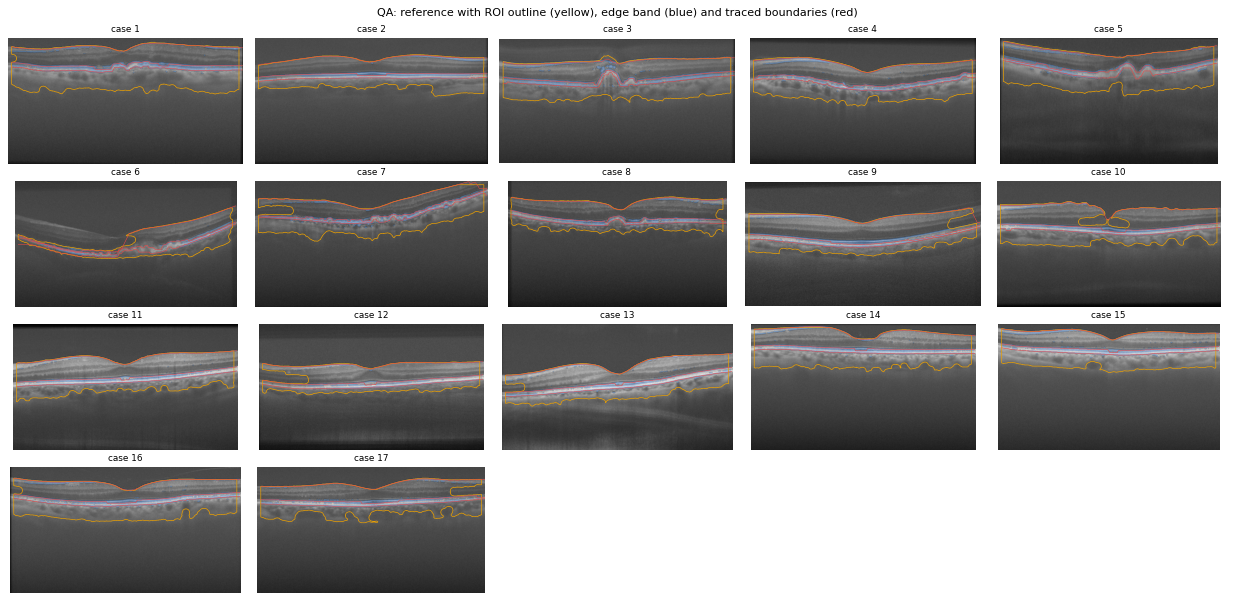

section 1: 9.8 s


In [9]:
t0 = time.perf_counter()
for cid in CASES:
    path = CACHE / "base" / f"case{cid:02d}.npz"
    if path.exists() and not FORCE:
        continue
    raw, ref = read_case(cid)
    roi = roi_mask(ref.astype(np.float64))
    edge = edge_mask(ref.astype(np.float64), roi)
    np.savez_compressed(path, Y=raw, ref=ref, roi=roi, edge=edge)

rows = []
for cid in CASES:
    with np.load(CACHE / "base" / f"case{cid:02d}.npz") as z:
        rows.append({"case": cid, "roi %": 100 * z["roi"].mean(), "edge band %": 100 * z["edge"].mean(),
                     "edge in roi %": 100 * (z["edge"] & z["roi"]).sum() / z["edge"].sum()})
mask_stats = pd.DataFrame(rows).set_index("case")
mask_stats.to_csv(CACHE / "mask_stats.csv")
display(mask_stats.round(1).T)

n = len(CASES)
ncol = min(n, 5)
fig, axes = plt.subplots(int(np.ceil(n / ncol)), ncol, figsize=(3.1 * ncol, 1.9 * int(np.ceil(n / ncol))), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, cid in zip(axes.ravel(), CASES):
    with np.load(CACHE / "base" / f"case{cid:02d}.npz") as z:
        ref, roi, edge = z["ref"].astype(np.float64), z["roi"], z["edge"]
    ax.imshow(ref, vmin=0, vmax=255)
    ax.contour(roi, levels=[0.5], colors=["#eda100"], linewidths=0.6)
    ax.imshow(np.ma.masked_where(~edge, edge), cmap=LinearSegmentedColormap.from_list("e", ["#2a78d6", "#2a78d6"]),
              alpha=0.35)
    for p in trace_boundaries(ref[:, DROP_COLS:], roi[:, DROP_COLS:]):
        ax.plot(np.arange(DROP_COLS, ref.shape[1]), p, color="#e34948", lw=0.5)
    ax.set_title(f"case {cid}", fontsize=8)
fig.suptitle("QA: reference with ROI outline (yellow), edge band (blue) and traced boundaries (red)", fontsize=10)
fig.tight_layout()
savefig(fig, "fig_qa_masks.png")
mark("1", t0)

## 2. Base K-SVD and TGV outputs

**Purpose:** reuse the stored outputs of `Comparison/` and generate the four missing tuning cases with exactly the same
frozen settings. Nothing is re-tuned, and the repo's files are only read.

In [10]:
t0 = time.perf_counter()
log_text = (REPO / "Comparison" / "outputs" / "run_log.txt").read_text()
assert "TGV    best {'alpha': 0.2, 'beta': 1.0}" in log_text and "K-SVD  best {'omp_C': 1.6, 'lambda_scale': 3.0}" in log_text


def run_base(y):
    return (np.round(M.denoise("KSVD", y, KSVD_PARAMS)[0]).astype(np.uint8),
            np.round(M.denoise("TGV", y, TGV_PARAMS)[0]).astype(np.uint8))


provenance = {}
for cid in CASES:
    path = CACHE / "base" / f"case{cid:02d}_outputs.npz"
    ks, tg = STORED_DIR / f"case{cid:02d}_K_SVD.tif", STORED_DIR / f"case{cid:02d}_TGV.tif"
    if path.exists() and not FORCE:
        continue
    if ks.exists() and tg.exists():
        XK, XT = tifffile.imread(ks), tifffile.imread(tg)
    else:
        print(f"case {cid}: not stored, running K-SVD and TGV")
        XK, XT = run_base(read_case(cid)[0].astype(np.float64))
    np.savez_compressed(path, XK=XK, XT=XT)

# the generated outputs must match the stored ones when the same code runs on a stored case
y13 = read_case(13)[0].astype(np.float64)
XK_new, XT_new = run_base(y13)
diff_k = np.abs(XK_new.astype(int) - tifffile.imread(STORED_DIR / "case13_K_SVD.tif").astype(int)).max()
diff_t = np.abs(XT_new.astype(int) - tifffile.imread(STORED_DIR / "case13_TGV.tif").astype(int)).max()
record_test("repo code reproduces the stored outputs (case 13)", diff_k <= 1 and diff_t <= 1,
            f"max |difference|: K-SVD {diff_k}, TGV {diff_t} grey levels")

# the metrics of this notebook must agree with the numbers Comparison/ reported
stored = pd.read_csv(REPO / "Comparison" / "outputs" / "metrics_per_image.csv")
rows = []
for cid in [c for c in CASES if c in EVAL_IDS]:
    B = base(cid)
    for name, X in (("K-SVD", B["XK"]), ("TGV", B["XT"])):
        s = stored[(stored["case"] == cid) & (stored["method"] == name)].iloc[0]
        rows.append({"case": cid, "method": name, "PSNR": M.psnr(B["ref"], X), "stored PSNR": s["PSNR"],
                     "SSIM": M.ssim(B["ref"], X), "stored SSIM": s["SSIM"], "EPI": M.epi(B["ref"], X),
                     "stored EPI": s["EPI"]})
check = pd.DataFrame(rows)
check.to_csv(CACHE / "base_metrics_check.csv", index=False)
gap = (check["PSNR"] - check["stored PSNR"]).abs().max()
record_test("stored outputs match the PSNR reported by Comparison/", gap < 0.02,
            f"largest difference {gap:.4f} dB (from rounding to uint8)")
display(check.groupby("method")[["PSNR", "stored PSNR", "SSIM", "stored SSIM", "EPI", "stored EPI"]].mean().round(4))
mark("2", t0)

[PASS] repo code reproduces the stored outputs (case 13): max |difference|: K-SVD 0, TGV 0 grey levels
[PASS] stored outputs match the PSNR reported by Comparison/: largest difference 0.0054 dB (from rounding to uint8)


,PSNR,stored PSNR,SSIM,stored SSIM,EPI,stored EPI
method,,,,,,
K-SVD,27.3920,27.3954,0.6695,0.6701,0.5774,0.5782
TGV,27.3485,27.3518,0.6749,0.6755,0.5701,0.5713


section 2: 17.6 s


## 3. Diagnostics

**Purpose:** before fitting anything, measure how the two methods' errors differ and which method wins where. These
diagnostics use the reference, so they describe the data and no method ever sees them at test time.

In [11]:
t0 = time.perf_counter()
rows_c, rows_b = [], []
for cid in EVAL_IDS:
    B = base(cid)
    ek, et = np.asarray(B["XK"] - B["ref"], np.float64), np.asarray(B["XT"] - B["ref"], np.float64)
    whole = np.ones_like(B["roi"])
    for name, m in (("whole", whole), ("roi", B["roi"]), ("edge", B["edge"])):
        rows_c.append({"case": cid, "region": name, "r": np.corrcoef(ek[m], et[m])[0, 1],
                       "rmse_d": float(np.sqrt(((ek - et)[m] ** 2).mean()))})
    for meth, err in (("K-SVD", ek), ("TGV", et)):
        split = band_split(err)
        for band in BANDS:
            for name, m in (("whole", whole), ("roi", B["roi"]), ("edge", B["edge"])):
                rows_b.append({"case": cid, "method": meth, "band": band, "region": name,
                               "energy": float((split[band][m] ** 2).mean())})
err_corr, band_err = pd.DataFrame(rows_c), pd.DataFrame(rows_b)
err_corr.to_csv(CACHE / "error_correlation.csv", index=False)
band_err.to_csv(CACHE / "band_errors.csv", index=False)
print(f"Correlation between the K-SVD and TGV errors, and rms of d = X_K - X_T (mean over {len(EVAL_IDS)} images)")
display(err_corr.groupby("region")[["r", "rmse_d"]].agg(["mean", "std"]).round(3))
print("Band-wise error energy (grey levels^2, mean over images) in the ROI")
display(band_err[band_err["region"] == "roi"].pivot_table(index="band", columns="method", values="energy").loc[list(BANDS)].round(2))

Correlation between the K-SVD and TGV errors, and rms of d = X_K - X_T (mean over 13 images)


r        rmse_d       
         mean    std   mean    std
region                            
edge    0.948  0.032  5.938  1.532
roi     0.966  0.018  3.407  0.759
whole   0.971  0.008  2.473  0.315

Band-wise error energy (grey levels^2, mean over images) in the ROI


method,K-SVD,TGV
band,,
low,71.64,71.82
mid,24.34,25.94
high,73.52,76.25


In [12]:
# winner maps: per 15x15 window, which method has the lower squared error; plus a smoothed version
rows = []
for cid in EVAL_IDS:
    B = base(cid)
    se_k = ndimage.uniform_filter(np.asarray(B["XK"] - B["ref"], np.float64) ** 2, WINNER_WIN)
    se_t = ndimage.uniform_filter(np.asarray(B["XT"] - B["ref"], np.float64) ** 2, WINNER_WIN)
    win = (se_k < se_t).astype(np.float32)
    np.savez_compressed(CACHE / "winners" / f"winner_case{cid:02d}.npz", winner=win, smooth=gs(win, WINNER_SMOOTH))
    rows.append({"case": cid, "K-SVD wins ROI %": 100 * win[B["roi"]].mean(), "K-SVD wins edge %": 100 * win[B["edge"]].mean()})
winners = pd.DataFrame(rows).set_index("case")
winners.to_csv(CACHE / "winner_fractions.csv")
display(winners.round(1).T)

mark("3", t0)

case,2,3,5,6,8,9,11,12,13,14,15,16,17
K-SVD wins ROI %,67.000000,63.799999,62.599998,51.200001,54.900002,54.099998,55.5,59.299999,51.799999,61.099998,60.400002,67.800003,61.299999
K-SVD wins edge %,63.599998,53.599998,33.700001,31.200001,66.400002,29.400000,63.0,70.000000,43.400002,69.500000,49.900002,74.900002,54.000000


section 3: 2.6 s


## 4. Feature maps

**Purpose:** compute the test-time features from $X_K$, $X_T$ and $Y$ only, and draw the fixed training sample of each
case. The training targets are stored with the sample and never used for prediction.

In [13]:
t0 = time.perf_counter()
rows = []
for cid in CASES:
    fpath, spath = CACHE / "features" / f"case{cid:02d}.npz", CACHE / "samples" / f"case{cid:02d}.npz"
    if fpath.exists() and spath.exists() and not FORCE:
        continue
    B = base(cid)
    F = compute_features(B["XK"], B["XT"], B["Y"])
    np.savez(fpath, **F)
    rng = np.random.default_rng([SEED, cid])
    idx = rng.choice(np.flatnonzero(B["roi"]), size=min(SAMPLES_PER_CASE, int(B["roi"].sum())), replace=False)
    d = np.asarray(B["XK"], np.float64) - B["XT"]
    e = np.asarray(B["ref"], np.float64) - B["XT"]
    w_t, rel = local_best_weight(np.asarray(B["ref"], np.float64), np.asarray(B["XK"], np.float64),
                                    np.asarray(B["XT"], np.float64), HGB_WINDOW)
    bands = np.column_stack([b.ravel()[idx] for b in pyramid_bands(d)]).astype(np.float32)
    np.savez(spath, idx=idx, e=e.ravel()[idx].astype(np.float32), d=d.ravel()[idx].astype(np.float32),
             edge=B["edge"].ravel()[idx], w_t=w_t.ravel()[idx].astype(np.float32), rel=rel.ravel()[idx].astype(np.float32),
             bands=bands, **{k: v.ravel()[idx] for k, v in F.items()})
    del F

# which features carry any information about the local best weight? (a diagnostic; nothing is fitted here)
rows = []
for cid in EVAL_IDS:
    S = samples(cid)
    for name in ("g", "vy", "va", "c", "dmag", "depth", "bright"):
        rows.append({"case": cid, "feature": name, "spearman": stats.spearmanr(S[fkey(name, 2)], S["w_t"]).statistic})
feat_corr = pd.DataFrame(rows)
feat_corr.to_csv(CACHE / "feature_vs_best_weight.csv", index=False)
print("Spearman correlation of each feature (scale 2) with the sliding 15 px best weight, mean and s.d. over images")
display(feat_corr.groupby("feature")["spearman"].agg(["mean", "std"]).round(3).T)

# per-case exact ROI sums, for the closed-form global weight
rows, table = [], []
for cid in CASES:
    B = base(cid)
    d, e = np.asarray(B["XK"], np.float64) - B["XT"], np.asarray(B["ref"], np.float64) - B["XT"]
    r = B["roi"]
    wt = 1.0 + EDGE_BETA * B["edge"]
    rows.append({"case": cid, "sum_ed": (e * d)[r].sum(), "sum_dd": (d * d)[r].sum(),
                 "sum_ed_w": (wt * e * d)[r].sum(), "sum_dd_w": (wt * d * d)[r].sum()})
    for s in COMPLEMENTARY_SIGMAS:
        for name, X in (("W9a LT+HK", comp_filter(B["XT"], B["XK"], s)), ("W9b LK+HT", comp_filter(B["XK"], B["XT"], s))):
            table.append({"case": cid, "method": name, "sigma": s, "mse": ((B["ref"] - X)[r] ** 2).mean(),
                          "mse_w": (wt[r] * (B["ref"] - X)[r] ** 2).mean()})
pd.DataFrame(rows).to_csv(CACHE / "roi_sums.csv", index=False)
pd.DataFrame(table).to_csv(CACHE / "w9_table.csv", index=False)
mark("4", t0)

Spearman correlation of each feature (scale 2) with the sliding 15 px best weight, mean and s.d. over images


feature,bright,c,depth,dmag,g,va,vy
mean,-0.070,-0.091,0.088,-0.053,-0.015,-0.027,0.011
std,0.139,0.114,0.130,0.113,0.106,0.126,0.078


section 4: 6.3 s


## 5. Weighting functions

**Purpose:** list what is compared and check the fusion on real images. The fitting code itself lives in section 0, so
that any later section can run without this one.

| ID | Weighting function | Learned on training cases | Selected by inner CV |
|---|---|---|---|
| W0 | K-SVD only ($w=1$), TGV only ($w=0$) | none | none |
| W1 | global constant $\theta$, closed form | $\theta$ | none |
| W2 to W6 | $w=\mathrm{sigmoid}(a z+b)$ on $g$, $v_Y$, $v_A$, $c$, $d_{mag}$, depth, brightness | $a,b$ | feature scale, post-smoothing |
| W7a | $w=\mathrm{clip}(\theta^T\phi,0,1)$, ridge in closed form | $\theta$ | scale, ridge, post-smoothing |
| W7b | the same with $\theta$ constrained so $w\in[0,1]$ on training pixels (QP) | $\theta$ | scale, post-smoothing |
| W8 | gradient boosting predicting the local best $w$ (computed from the reference on training cases only). **Overfitting-prone.** | trees | leaves, post-smoothing |
| W9a, W9b | $L_s(X_T)+(I-L_s)X_K$ and the swapped assignment | none | cutoff $s$ |
| W10a | 4-level pyramid, one global weight per level | level weights | none |
| W10b | 4-level pyramid, each level weight varying linearly with $g$ | level coefficients | feature scale |
| WS | in each fold, the spatial method (W2 to W8) with the lowest inner-CV MSE | selection | selection |
| C1, C2 | controls on WS's map: blocks shuffled, and a random smooth map with the same mean | none | none |

W9 and W10 blend frequency bands, not pixels, so their output is **not** pointwise between $X_K$ and $X_T$. The between-
inputs assertion therefore applies to W0 to W8, WS and the controls (see `ASSUMPTIONS.md`).

In [14]:
t0 = time.perf_counter()
cid = EVAL_IDS[0]
B = base(cid)
record_test("w=0 reproduces TGV exactly (real image)", np.array_equal(fuse(B["XK"], B["XT"], np.zeros_like(B["XK"])), np.asarray(B["XT"], np.float64)))
record_test("w=1 reproduces K-SVD exactly (real image)", np.array_equal(fuse(B["XK"], B["XT"], np.ones_like(B["XK"])), np.asarray(B["XK"], np.float64)))
bands = pyramid_bands(np.asarray(B["XK"], np.float64) - B["XT"])
record_test("pyramid levels sum to d", np.abs(sum(bands) - (np.asarray(B["XK"], np.float64) - B["XT"])).max() < 1e-9)
record_test("pyramid with all weights 1 reproduces K-SVD",
            np.abs(pyr_output(B["XK"], B["XT"], [1.0] * len(bands)) - B["XK"]).max() < 1e-9)
print("Grid sizes per method:", {m: len(hp_grid(m)) for m in SPATIAL})
mark("5", t0)

[PASS] w=0 reproduces TGV exactly (real image): 
[PASS] w=1 reproduces K-SVD exactly (real image): 
[PASS] pyramid levels sum to d: 
[PASS] pyramid with all weights 1 reproduces K-SVD: 
Grid sizes per method: {'W2 g': 3, 'W3a vY': 3, 'W3b vA': 3, 'W4 c': 3, 'W5 dmag': 3, 'W6a depth': 1, 'W6b bright': 3, 'W7a ridge': 9, 'W7b boxed': 3, 'W8 HGB': 2}
section 5: 0.1 s


## 6. Leave-one-case-out evaluation

**Purpose:** for every scored case, fit every method on the other cases only and apply it to the held-out case. Each
result is written as soon as it exists, so an interrupted run can be resumed.

Every fold trains on all the other cases, including the four tuning cases, and scores only its test case. The nesting
is asserted in `train_cases` and `select_and_fit`, and a manifest is checked below.

In [15]:
t0 = time.perf_counter()


def write_result(cid, method, payload, info):
    d = CACHE / "folds" / f"case{cid:02d}"
    d.mkdir(exist_ok=True)
    np.savez_compressed(d / f"{slug(method)}.npz", **payload)
    (d / f"{slug(method)}.json").write_text(json.dumps(info, indent=1, default=float))


def done(cid, method):
    return (CACHE / "folds" / f"case{cid:02d}" / f"{slug(method)}.json").exists() and not FORCE


def saturation(w, roi):
    return {"frac_0": float((w[roi] <= 1e-3).mean()), "frac_1": float((w[roi] >= 1 - 1e-3).mean()),
            "mean_w": float(w[roi].mean()), "std_w": float(w[roi].std())}


def spatial_task(cid, method):
    if done(cid, method):
        return
    model, hp, post, score, score_nopost = select_and_fit(method, cid)
    B = base(cid)
    raw = predict_w(model, cid)
    w = apply_post(raw, post, 0.5 * (B["XK"] + B["XT"])).astype(np.float32)
    fuse(B["XK"], B["XT"], w)
    info = {"method": method, "test": cid, "train": model["cases"], "hp": hp, "post": post, "inner_mse": score,
            "inner_mse_nopost": score_nopost, **saturation(w, B["roi"]),
            **{k: (model[k].tolist() if hasattr(model[k], "tolist") else model[k])
               for k in ("a", "b", "theta", "mu", "sd", "violation") if k in model}}
    write_result(cid, method, {"w": w, "w_raw": raw}, info)
    print(f"  case {cid:2d} {method:11s} hp {hp} post {post} inner MSE {score:.2f}", flush=True)


def global_and_freq_task(cid):
    train = train_cases(cid)
    B = base(cid)
    sums = pd.read_csv(CACHE / "roi_sums.csv").set_index("case").loc[train]
    if not done(cid, "W1 theta"):
        theta = theta_closed_form(sums["sum_ed"].sum(), sums["sum_dd"].sum())
        w = np.full(B["XK"].shape, theta, np.float32)
        fuse(B["XK"], B["XT"], w)
        write_result(cid, "W1 theta", {"w": w, "w_raw": w}, {"method": "W1 theta", "test": cid, "train": train,
                                                             "theta": theta, **saturation(w, B["roi"])})
    table = pd.read_csv(CACHE / "w9_table.csv")
    table = table[table["case"].isin(train)]
    for name, low, high in (("W9a LT+HK", B["XT"], B["XK"]), ("W9b LK+HT", B["XK"], B["XT"])):
        if not done(cid, name):
            means = table[table["method"] == name].groupby("sigma")["mse"].mean()
            s = float(means.idxmin())
            write_result(cid, name, {"X": comp_filter(low, high, s).astype(np.float32)},
                         {"method": name, "test": cid, "train": train, "sigma": s, "inner_mse": float(means.min())})
    if not done(cid, "W10a pyr"):
        wl = fit_pyr_global(train)
        write_result(cid, "W10a pyr", {"X": pyr_output(B["XK"], B["XT"], list(wl)).astype(np.float32)},
                     {"method": "W10a pyr", "test": cid, "train": train, "level_weights": wl.tolist()})
    if not done(cid, "W10b pyr-g"):
        folds = inner_folds(train)
        scores = {s: np.mean([pyr_g_loss(fit_pyr_g(tr, s), val) for tr, val in folds]) for s in SCALES}
        s = min(scores, key=scores.get)
        m = fit_pyr_g(train, s)
        z = (feature_map(cid, "g", s) - m["mu"]) / m["sd"]
        wl = [np.clip(a + b * z, 0, 1) for a, b in zip(m["a"], m["b"])]
        write_result(cid, "W10b pyr-g", {"X": pyr_output(B["XK"], B["XT"], wl).astype(np.float32)},
                     {"method": "W10b pyr-g", "test": cid, "train": train, "s": s, "a": m["a"].tolist(),
                      "b": m["b"].tolist(), "inner_mse": float(scores[s])})


run_threads(global_and_freq_task, [(c,) for c in EVAL_IDS])
print("W1, W9, W10 done")
sigmoid_and_linear = [m for m in SPATIAL if SPATIAL[m][0] != "hgb"]
run_threads(spatial_task, [(c, m) for c in EVAL_IDS for m in sigmoid_and_linear])
for c in EVAL_IDS:                 # HGB uses all cores by itself, so it isn't run inside the thread pool
    spatial_task(c, "W8 HGB")
mark("6a", t0)

W1, W9, W10 done
section 6a: 0.0 s


In [16]:
t0 = time.perf_counter()
# WS: the fold's spatial method with the lowest inner-CV ROI MSE, chosen without the test case; then the two controls
for cid in EVAL_IDS:
    infos = {m: json.loads((CACHE / "folds" / f"case{cid:02d}" / f"{slug(m)}.json").read_text()) for m in SPATIAL}
    chosen = min(infos, key=lambda m: infos[m]["inner_mse"])
    with np.load(CACHE / "folds" / f"case{cid:02d}" / f"{slug(chosen)}.npz") as z:
        w, raw = z["w"], z["w_raw"]
    B = base(cid)
    write_result(cid, "WS selected", {"w": w, "w_raw": raw}, {"method": "WS selected", "test": cid, "chosen": chosen,
                                                              "train": infos[chosen]["train"], **saturation(w, B["roi"])})
    rng = np.random.default_rng([SEED, cid, 1])
    c1 = shuffle_blocks(w, SHUFFLE_BLOCK, rng)
    c2 = random_smooth(w.shape, float(w.mean()), RANDOM_SMOOTH_SIGMA, rng)
    fuse(B["XK"], B["XT"], c1), fuse(B["XK"], B["XT"], c2)
    write_result(cid, "C1 shuffled", {"w": c1, "w_raw": c1}, {"method": "C1 shuffled", "test": cid, **saturation(c1, B["roi"])})
    write_result(cid, "C2 random", {"w": c2, "w_raw": c2}, {"method": "C2 random", "test": cid, **saturation(c2, B["roi"])})

# no-leakage check, from what the fits actually stored
manifest, leaks = {}, 0
for cid in EVAL_IDS:
    trains = {m: json.loads((CACHE / "folds" / f"case{cid:02d}" / f"{slug(m)}.json").read_text()).get("train")
              for m in DEPLOYABLE}
    manifest[cid] = {m: t for m, t in trains.items()}
    leaks += sum(cid in (t or []) for t in trains.values())
(CACHE / "fold_manifest.json").write_text(json.dumps(manifest, indent=1))
record_test("no test case appears in its own training set", leaks == 0 and all(t for v in manifest.values() for t in v.values()),
            f"{len(manifest)} folds x {len(DEPLOYABLE)} methods checked")

# fold-to-fold stability and saturation
rows = []
for cid in EVAL_IDS:
    for m in ["W1 theta"] + list(SPATIAL) + ["WS selected"] + CONTROLS:
        info = json.loads((CACHE / "folds" / f"case{cid:02d}" / f"{slug(m)}.json").read_text())
        flat = {k: info.get(k) for k in ("frac_0", "frac_1", "mean_w", "std_w", "a", "b", "chosen", "violation")}
        flat.update(theta=info["theta"] if m == "W1 theta" else None, s=(info.get("hp") or {}).get("s"),
                    lam=(info.get("hp") or {}).get("lam"), leaves=(info.get("hp") or {}).get("leaves"),
                    post=f"{info['post'][0]} {info['post'][1]}" if info.get("post") else None)
        rows.append({"case": cid, "method": m, **flat})
fold_params = pd.DataFrame(rows)
fold_params.to_csv(CACHE / "fold_params.csv", index=False)
print("Fraction of ROI pixels with w at 0 or 1, and mean w over the folds")
display(fold_params.groupby("method", sort=False)[["frac_0", "frac_1", "mean_w", "std_w"]].mean().round(3))
print("Fitted sigmoid parameters: mean and s.d. over the folds")
display(fold_params[fold_params["a"].notna()].groupby("method", sort=False)[["a", "b"]].agg(["mean", "std"]).round(3))
theta_values = fold_params.loc[fold_params["method"] == "W1 theta", "theta"].astype(float)
print(f"W1 theta over folds: mean {theta_values.mean():.3f}, s.d. {theta_values.std():.3f}, "
      f"range [{theta_values.min():.3f}, {theta_values.max():.3f}]")
print("Spatial method picked by WS:", fold_params.loc[fold_params["method"] == "WS selected", "chosen"].value_counts().to_dict())
mark("6b", t0)

[PASS] no test case appears in its own training set: 13 folds x 16 methods checked
Fraction of ROI pixels with w at 0 or 1, and mean w over the folds


,frac_0,frac_1,mean_w,std_w
method,,,,
W1 theta,0.0,0.000,0.787,0.000
W2 g,0.0,0.000,0.804,0.021
W3a vY,0.0,0.000,0.805,0.059
W3b vA,0.0,0.000,0.838,0.043
W4 c,0.0,0.000,0.821,0.112
W5 dmag,0.0,0.000,0.865,0.039
W6a depth,0.0,0.000,0.799,0.074
W6b bright,0.0,0.000,0.823,0.031
W7a ridge,0.0,0.123,0.775,0.176


Fitted sigmoid parameters: mean and s.d. over the folds


a             b       
             mean    std   mean    std
method                                
W2 g       -0.222  0.111  1.435  0.156
W3a vY     -0.422  0.040  1.471  0.113
W3b vA     -0.445  0.077  1.735  0.085
W4 c       -1.204  0.115  1.978  0.110
W5 dmag    -0.348  0.070  1.924  0.150
W6a depth  -0.716  0.156  1.581  0.209
W6b bright -0.286  0.176  1.528  0.247

W1 theta over folds: mean 0.787, s.d. 0.018, range [0.761, 0.821]
Spatial method picked by WS: {'W7a ridge': 13}
section 6b: 12.3 s


## 7. Metrics

**Purpose:** score every output on every held-out image with one metric function.

W2 to W8 and WS are also scored without their post-smoothing, for the ablation in section 10.

In [17]:
t0 = time.perf_counter()
NO_POST = [f"{m} (no post)" for m in SPATIAL]


def eval_task(cid, method):
    return {"case": cid, "method": method, "split": "held-out" if cid in HELD_OUT_IDS else "other",
            **eval_output(cid, output_of(cid, method)[0])}


for cid in EVAL_IDS:
    ref_pack(cid)                  # computed once, before the threads share it
metrics_df = pd.DataFrame(run_threads(eval_task, [(c, m) for c in EVAL_IDS for m in ALL_METHODS + NO_POST]))
metrics_df.to_csv(CACHE / "metrics_per_image.csv", index=False)
ref_rise = {c: float(np.nanmean([rise_along(ref_pack(c)["ref"][:, DROP_COLS:], p) for p in ref_pack(c)["paths"]])) for c in EVAL_IDS}
(CACHE / "reference_rise.json").write_text(json.dumps(ref_rise, indent=1))

# reproducing the repo's metric functions on the two base methods
chk = metrics_df[metrics_df["method"].isin(BASE_METHODS)]
same = all(abs(r.whole_psnr - M.psnr(base(r.case)["ref"], output_of(r.case, r.method)[0])) < 1e-9
           and abs(r.whole_ssim - M.ssim(base(r.case)["ref"], output_of(r.case, r.method)[0])) < 1e-9
           for r in chk.itertuples())
record_test("whole-image PSNR/SSIM equal the repo's functions", same)
self_check = eval_output(EVAL_IDS[0], ref_pack(EVAL_IDS[0])["ref"])
record_test("the reference scores zero boundary error against itself", self_check["bnd_mae"] < 1e-9, f"{self_check['bnd_mae']:.3g} px")
rng = np.random.default_rng([SEED, 7])
moves = []
for c in EVAL_IDS:
    P = ref_pack(c)
    noisy = P["ref"][:, DROP_COLS:] + rng.normal(0, 2, P["ref"][:, DROP_COLS:].shape)
    moves.append(np.abs(trace_boundaries(noisy, P["roi"][:, DROP_COLS:]) - P["paths"]).mean(axis=1).max())
record_test("the tracer is stable: noise of s.d. 2 on the reference moves no boundary by 0.5 px or more", max(moves) < 0.5, f"worst {max(moves):.2f} px")

mark("7", t0)

[PASS] whole-image PSNR/SSIM equal the repo's functions: 
[PASS] the reference scores zero boundary error against itself: 0 px
[PASS] the tracer is stable: noise of s.d. 2 on the reference moves no boundary by 0.5 px or more: worst 0.16 px
section 7: 149.5 s


## 8. Statistics and tables

**Purpose:** compare each method per image with the better single method and with the global weight, with Holm
correction, then name the winner of the primary endpoint.

For each metric, "the better single method" is whichever of K-SVD and TGV has the better mean on that metric, which
gives fusion the hardest available baseline. The winner is read off the test results, so its margin is optimistic;
**WS** is the honest estimate of what picking a method without the test case would give.

In [18]:
t0 = time.perf_counter()
df = load_metrics()
summary_rows = []
for m in df["method"].unique():
    sub = df[df["method"] == m]
    for key in METRICS:
        summary_rows.append({"method": m, "metric": key, "mean": sub[key].mean(), "std": sub[key].std(ddof=1), "n": len(sub)})
summary = pd.DataFrame(summary_rows)
summary.to_csv(CACHE / "summary_long.csv", index=False)
means = summary.pivot(index="method", columns="metric", values="mean")
order = [m for m in ALL_METHODS if m in means.index]
print(f"Mean over n = {df['case'].nunique()} images")
display(means.loc[order, list(METRICS)].round(3))

rng = np.random.default_rng(SEED)
best_single = {k: means.loc[BASE_METHODS, k].idxmax() if METRICS[k][1] else means.loc[BASE_METHODS, k].idxmin() for k in METRICS}
rows = []
for key in METRICS:
    wide = df.pivot(index="case", columns="method", values=key)
    for baseline_name, baseline in (("best single", best_single[key]), ("W1 theta", "W1 theta")):
        cand = [m for m in DEPLOYABLE + CONTROLS if m != baseline]
        out = [{"metric": key, "baseline_kind": baseline_name, "baseline": baseline, "method": m,
                **paired_stats(wide[m].values, wide[baseline].values, METRICS[key][1], rng)} for m in cand]
        for r, ph in zip(out, holm([r["p"] for r in out])):
            r["p_holm"] = ph
        rows += out
stat_df = pd.DataFrame(rows)
stat_df.to_csv(CACHE / "paired_stats.csv", index=False)

candidates = [m for m in DEPLOYABLE if m != "WS selected"]
hi = METRICS[PRIMARY][1]
winner = means.loc[candidates, PRIMARY].idxmax() if hi else means.loc[candidates, PRIMARY].idxmin()
second = means.loc[[c for c in candidates if c != winner], PRIMARY].idxmax() if hi else means.loc[[c for c in candidates if c != winner], PRIMARY].idxmin()
wide = df.pivot(index="case", columns="method", values=PRIMARY)
control_cmp = {f"{a} vs {b}": paired_stats(wide[a].values, wide[b].values, hi, rng)
               for a in (winner, "WS selected") for b in CONTROLS}
record = {"primary": PRIMARY, "winner": winner, "second": second, "best_single": best_single,
          "control_comparisons": control_cmp, "n": int(df["case"].nunique())}
(CACHE / "winner.json").write_text(json.dumps(record, indent=1))


def show_stats(kind, key):
    s = stat_df[(stat_df["baseline_kind"] == kind) & (stat_df["metric"] == key)].set_index("method")
    return s[["n", "mean", "sd", "ci_lo", "ci_hi", "wins", "dz", "p", "p_holm"]].round(4)


print(f"Winner on {METRICS[PRIMARY][0]}: {winner}; second: {second}; better single method: {best_single[PRIMARY]}")
print(f"\nImprovement over {best_single[PRIMARY]} on {METRICS[PRIMARY][0]} (positive = better, n = {record['n']})")
display(show_stats("best single", PRIMARY))
print(f"Improvement over W1 theta on {METRICS[PRIMARY][0]}")
display(show_stats("W1 theta", PRIMARY))
print(f"Improvement over the better single method on boundary MAE ({best_single['bnd_mae']})")
display(show_stats("best single", "bnd_mae"))
print("Improvement over the better single method and over W1 theta on EPI Sobel")
display(show_stats("best single", "epi"))
display(show_stats("W1 theta", "epi"))
significant = stat_df[stat_df["p_holm"] < 0.05].sort_values(["metric", "baseline_kind", "mean"], ascending=[True, True, False])
significant.to_csv(CACHE / "significant.csv", index=False)
print(f"Every comparison that survives Holm correction ({len(significant)} of {len(stat_df)}; positive = the method is better)")
display(significant[["metric", "baseline", "method", "mean", "ci_lo", "ci_hi", "wins", "n", "p_holm"]].round(4))
print("Against the shuffled and random controls")
display(pd.DataFrame(control_cmp).T[["mean", "sd", "ci_lo", "ci_hi", "wins", "p"]].round(4))
print(f"Held-out subgroup only (n = {df[df['split'] == 'held-out']['case'].nunique()}; the two-sided Wilcoxon can't go below p = 0.0625 at n = 5)")
held = df[df["split"] == "held-out"].groupby("method")[list(METRICS)].mean()
display(held.loc[[m for m in BASE_METHODS + ["W1 theta", winner, "WS selected"] if m in held.index], [PRIMARY, "bnd_mae", "roi_psnr", "enl"]].drop_duplicates().round(3))
mark("8", t0)

Mean over n = 13 images


metric,edge_ssim,edge_psnr,edge_gmsd,epi,epi_lap,bnd_mae,rise,roi_psnr,roi_ssim,cnr,msr,enl,sigma_flat
method,,,,,,,,,,,,,
K-SVD,0.686,22.386,0.183,0.577,0.337,1.677,7.956,24.989,0.642,4.553,7.759,161.420,8.436
TGV,0.674,22.148,0.182,0.570,0.325,1.621,9.696,24.829,0.639,4.526,7.647,142.380,8.495
W1 theta,0.688,22.403,0.181,0.585,0.344,1.661,8.429,24.996,0.643,4.576,7.756,160.665,8.402
W2 g,0.688,22.400,0.181,0.583,0.342,1.660,8.435,24.996,0.643,4.579,7.766,161.193,8.403
W3a vY,0.687,22.398,0.181,0.583,0.342,1.664,8.450,24.996,0.643,4.596,7.801,160.936,8.418
W3b vA,0.688,22.399,0.181,0.580,0.339,1.659,8.440,24.998,0.643,4.579,7.775,161.577,8.410
W4 c,0.687,22.385,0.181,0.577,0.336,1.637,8.672,24.999,0.643,4.589,7.798,161.367,8.406
W5 dmag,0.688,22.401,0.181,0.583,0.341,1.659,8.444,24.998,0.643,4.591,7.780,160.830,8.398
W6a depth,0.688,22.408,0.181,0.592,0.353,1.662,8.343,24.999,0.643,4.573,7.771,162.388,8.373


Winner on Edge SSIM: W8 HGB; second: W7b boxed; better single method: K-SVD

Improvement over K-SVD on Edge SSIM (positive = better, n = 13)


,n,mean,sd,ci_lo,ci_hi,wins,dz,p,p_holm
method,,,,,,,,,
W1 theta,13,0.0024,0.0042,0.0002,0.0045,7,0.5597,0.1677,1.0000
W2 g,13,0.0022,0.0046,-0.0001,0.0045,7,0.4817,0.1677,1.0000
W3a vY,13,0.0013,0.0050,-0.0012,0.0039,6,0.2670,0.3396,1.0000
W3b vA,13,0.0021,0.0045,-0.0003,0.0045,7,0.4639,0.1677,1.0000
W4 c,13,0.0014,0.0065,-0.0019,0.0048,6,0.2134,0.4548,1.0000
W5 dmag,13,0.0019,0.0048,-0.0006,0.0043,7,0.4041,0.2439,1.0000
W6a depth,13,0.0023,0.0046,-0.0000,0.0047,8,0.4913,0.1677,1.0000
W6b bright,13,0.0023,0.0038,0.0003,0.0042,9,0.5920,0.0681,1.0000
W7a ridge,13,0.0020,0.0068,-0.0015,0.0056,8,0.2948,0.4143,1.0000


Improvement over W1 theta on Edge SSIM


...

Against the shuffled and random controls


,mean,sd,ci_lo,ci_hi,wins,p
W8 HGB vs C1 shuffled,0.0027,0.0067,-0.0009,0.0060,8.0,0.1909
W8 HGB vs C2 random,0.0021,0.0068,-0.0017,0.0055,8.0,0.2734
WS selected vs C1 shuffled,0.0011,0.0051,-0.0015,0.0039,8.0,0.5879
WS selected vs C2 random,0.0006,0.0049,-0.0019,0.0032,7.0,0.8394


Held-out subgroup only (n = 5; the two-sided Wilcoxon can't go below p = 0.0625 at n = 5)


,edge_ssim,bnd_mae,roi_psnr,enl
method,,,,
K-SVD,0.653,1.329,24.917,127.772
TGV,0.643,1.221,24.759,118.777
W1 theta,0.655,1.304,24.921,127.626
W8 HGB,0.657,1.245,24.912,126.862
WS selected,0.655,1.291,24.929,127.603


section 8: 2.7 s


## 9. Figures

**Purpose:** all figures, at 300 dpi in `figures/`. Crop rule, fixed in advance: the boundary crop is the window with the
highest mean reference gradient in the ROI, and the speckle crop has the same width, starts at the same column and is
centred three quarters of the way down the retina at that column. Colour shows method family, which is the same in every
chart.

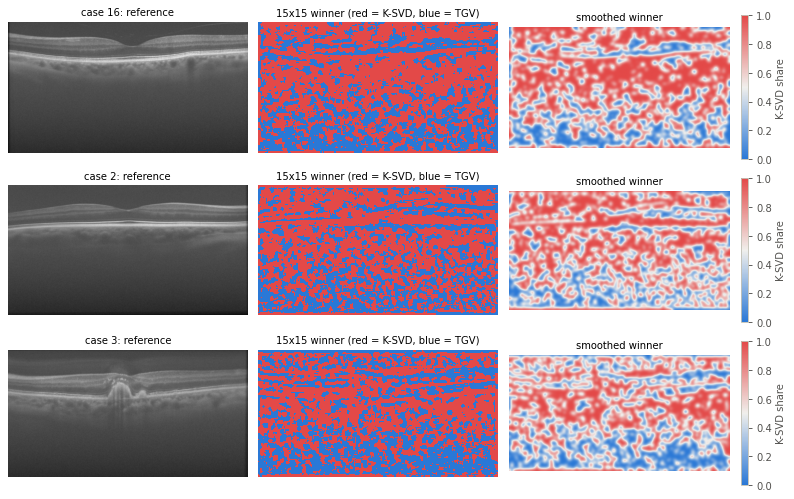

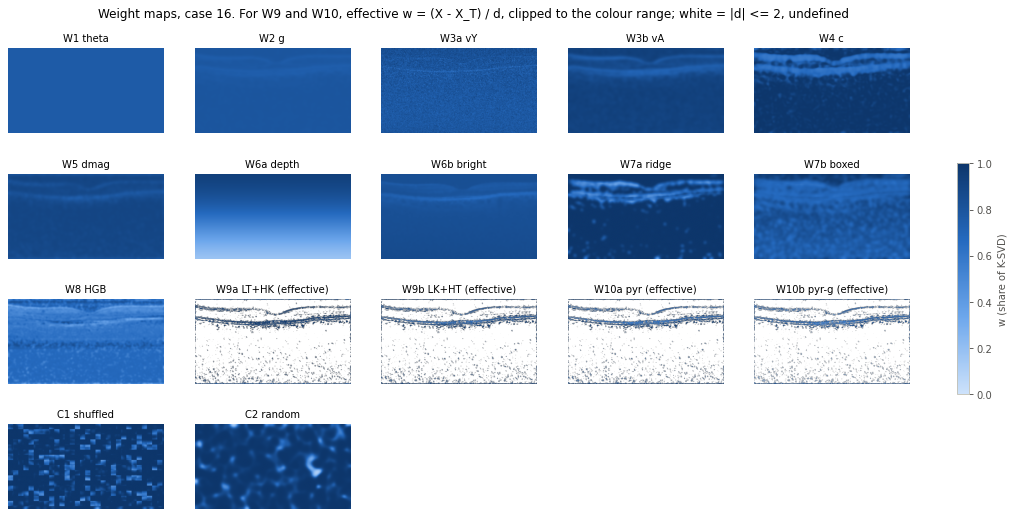

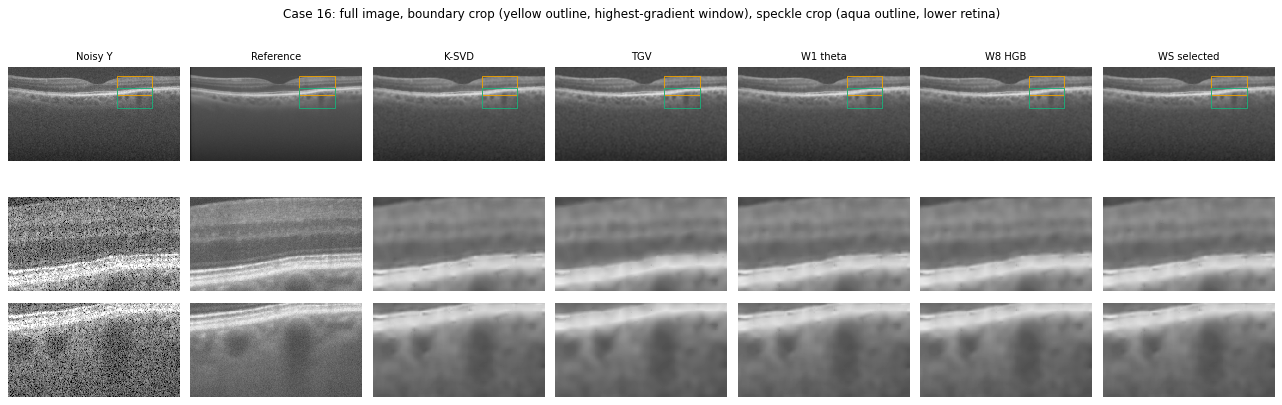

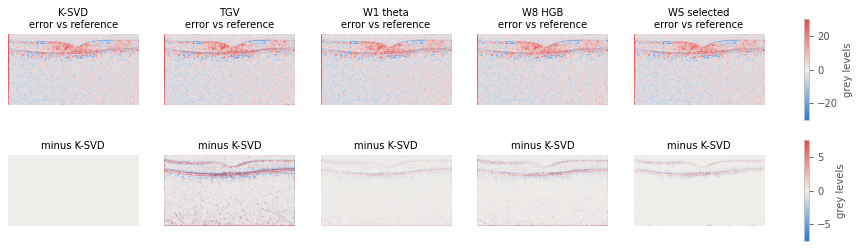

In [19]:
t0 = time.perf_counter()
df = load_metrics()
record = json.loads((CACHE / "winner.json").read_text())
winner, best_single = record["winner"], record["best_single"]
stat_df = pd.read_csv(CACHE / "paired_stats.csv")
fc = FIG_CASE if FIG_CASE in EVAL_IDS else EVAL_IDS[0]
B = base(fc)
SHORT = {m: m.split(" ")[0] for m in ALL_METHODS}
SHOWN = ["K-SVD", "TGV", "W1 theta", winner, "WS selected"]
SHOWN = list(dict.fromkeys(SHOWN))


def effective_w(cid, method):
    X, w = output_of(cid, method)
    if w is not None:
        return w
    Bc = base(cid)
    d = np.asarray(Bc["XK"], np.float64) - Bc["XT"]
    return np.where(np.abs(d) > 2, (X - Bc["XT"]) / np.where(np.abs(d) > 2, d, 1), np.nan)


def crop_windows(cid):
    Bc = base(cid)
    h, w = CROP_SHAPE
    g = ndimage.uniform_filter(grad_mag(gs(np.asarray(Bc["ref"], np.float64), 2.0)) * Bc["roi"], (h, w))
    r0, c0 = np.unravel_index(np.nanargmax(g[h // 2:-h // 2, w // 2:-w // 2]), (g.shape[0] - h, g.shape[1] - w))
    rows = np.flatnonzero(Bc["roi"][:, c0 + w // 2])
    rs = int(np.clip(rows[0] + 0.75 * (rows[-1] - rows[0]) - h / 2, 0, g.shape[0] - h))
    return (slice(int(r0), int(r0) + h), slice(int(c0), int(c0) + w)), (slice(rs, rs + h), slice(int(c0), int(c0) + w))


# winner maps
cases = list(dict.fromkeys([fc] + [c for c in EVAL_IDS if c != fc]))[:3]
fig, axes = plt.subplots(len(cases), 3, figsize=(10, 2.1 * len(cases)), squeeze=False)
for row, c in zip(axes, cases):
    with np.load(CACHE / "winners" / f"winner_case{c:02d}.npz") as z:
        win, smooth = z["winner"], z["smooth"]
    row[0].imshow(base(c)["ref"], vmin=0, vmax=255)
    row[0].set_title(f"case {c}: reference")
    row[1].imshow(win, cmap=DIV, vmin=0, vmax=1, interpolation="nearest")
    row[1].set_title("15x15 winner (red = K-SVD, blue = TGV)")
    im = row[2].imshow(smooth, cmap=DIV, vmin=0, vmax=1)
    row[2].set_title("smoothed winner")
    fig.colorbar(im, ax=row[2], fraction=0.03, label="K-SVD share")
    for ax in row:
        ax.axis("off")
fig.tight_layout()
savefig(fig, "fig_winner_maps.png")

# weight maps of every method
shown = ["W1 theta"] + list(SPATIAL) + FREQ_METHODS + CONTROLS
ncol = 5
fig, axes = plt.subplots(int(np.ceil(len(shown) / ncol)), ncol, figsize=(3.1 * ncol, 1.95 * int(np.ceil(len(shown) / ncol))))
for ax in axes.ravel():
    ax.axis("off")
for ax, m in zip(axes.ravel(), shown):
    im = ax.imshow(effective_w(fc, m), cmap=SEQ, vmin=0, vmax=1)
    ax.set_title(m + (" (effective)" if m in FREQ_METHODS else ""))
fig.colorbar(im, ax=axes, fraction=0.012, label="w (share of K-SVD)")
fig.suptitle(f"Weight maps, case {fc}. For W9 and W10, effective w = (X - X_T) / d, clipped to the colour range; white = |d| <= 2, undefined", y=0.93)
savefig(fig, "fig_weight_maps.png")

# fused results with crops
crops = crop_windows(fc)
panels = [("Noisy Y", B["Y"]), ("Reference", B["ref"])] + [(m, output_of(fc, m)[0]) for m in SHOWN]
fig, axes = plt.subplots(3, len(panels), figsize=(2.3 * len(panels), 5.2), gridspec_kw={"height_ratios": [1.45, 1, 1]})
for j, (name, X) in enumerate(panels):
    axes[0, j].imshow(X, vmin=0, vmax=255)
    axes[0, j].set_title(name)
    for (r, c), col in zip(crops, ("#eda100", "#1baf7a")):
        axes[0, j].add_patch(plt.Rectangle((c.start, r.start), c.stop - c.start, r.stop - r.start, fill=False, ec=col, lw=0.8))
    for i, (r, c) in enumerate(crops):
        axes[i + 1, j].imshow(X[r, c], vmin=0, vmax=255, interpolation="nearest")
    for ax in axes[:, j]:
        ax.axis("off")
fig.suptitle(f"Case {fc}: full image, boundary crop (yellow outline, highest-gradient window), speckle crop (aqua outline, lower retina)")
fig.tight_layout()
savefig(fig, "fig_fused_crops.png")

# error maps and differences to the better single method
errs = [(m, output_of(fc, m)[0] - B["ref"]) for m in SHOWN]
lim = np.percentile(np.abs(errs[0][1]), 99)
fig, axes = plt.subplots(2, len(SHOWN), figsize=(2.6 * len(SHOWN), 3.6))
for j, (m, e) in enumerate(errs):
    im0 = axes[0, j].imshow(e, cmap=DIV, vmin=-lim, vmax=lim)
    axes[0, j].set_title(f"{m}\nerror vs reference")
    delta = output_of(fc, m)[0] - output_of(fc, best_single[record["primary"]])[0]
    im1 = axes[1, j].imshow(delta, cmap=DIV, vmin=-lim / 4, vmax=lim / 4)
    axes[1, j].set_title(f"minus {best_single[record['primary']]}")
    for ax in axes[:, j]:
        ax.axis("off")
fig.colorbar(im0, ax=axes[0], fraction=0.012, label="grey levels")
fig.colorbar(im1, ax=axes[1], fraction=0.012, label="grey levels")
savefig(fig, "fig_error_and_difference_maps.png")

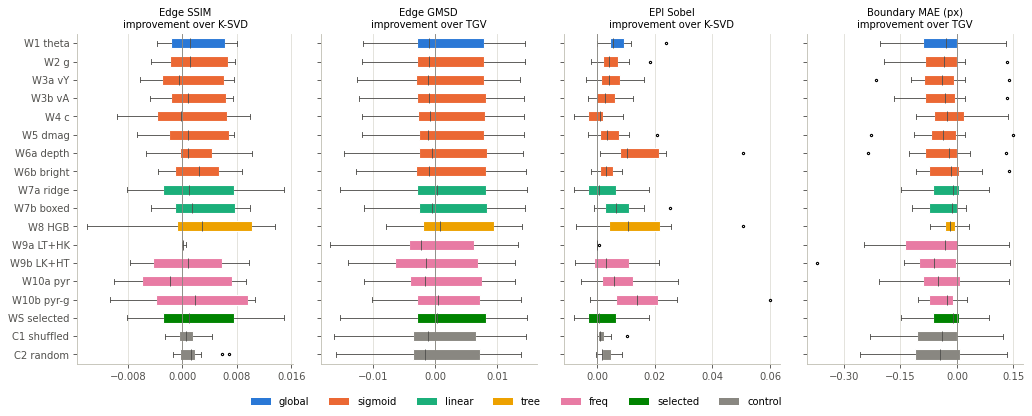

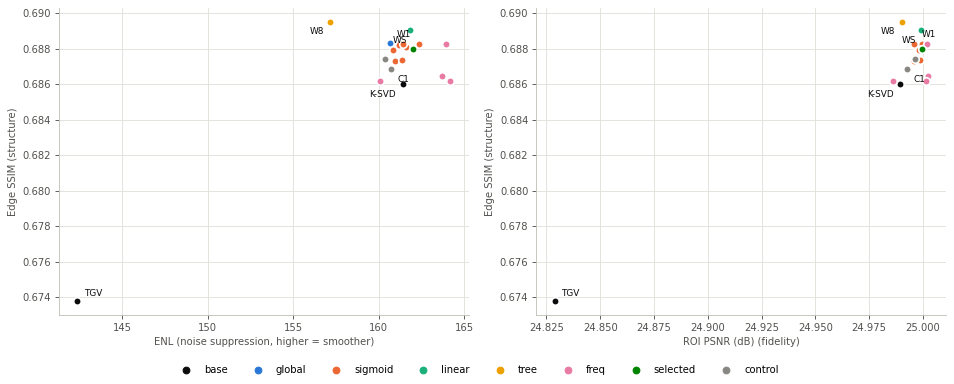

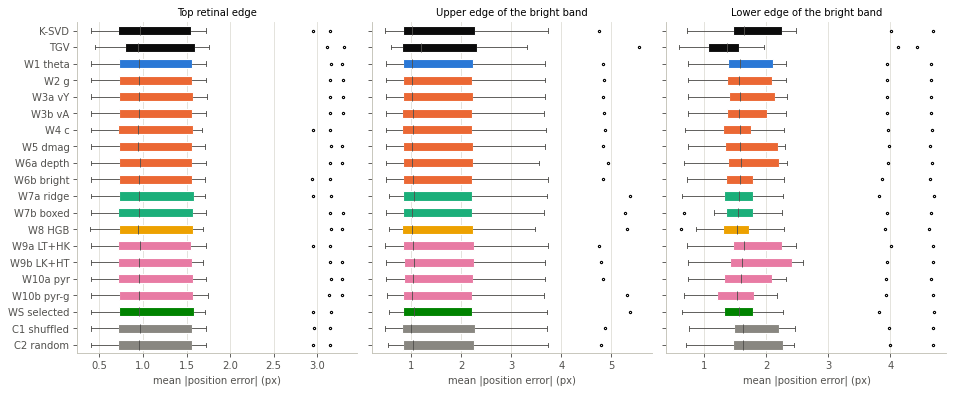

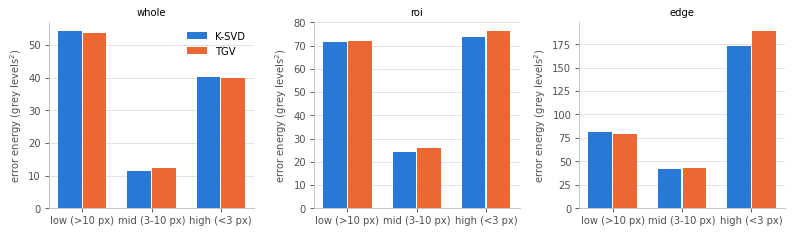

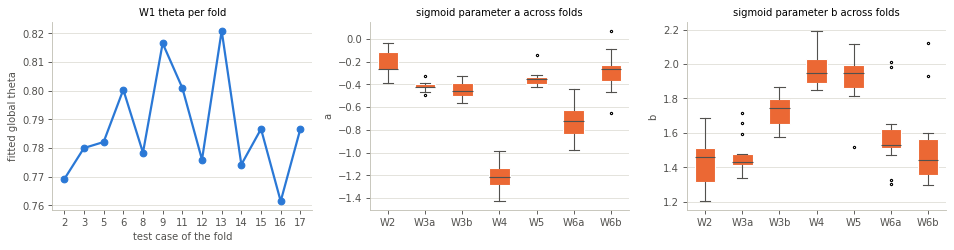

section 9: 11.6 s


In [20]:
# paired improvement over the better single method, per image
panel_metrics = ["edge_ssim", "edge_gmsd", "epi", "bnd_mae"]
methods_plot = [m for m in DEPLOYABLE + CONTROLS]
fig, axes = plt.subplots(1, 4, figsize=(13, 5.2), sharey=True)
for ax, key in zip(axes, panel_metrics):
    wide = df.pivot(index="case", columns="method", values=key)
    base_m = best_single[key]
    data = [(wide[m] - wide[base_m]) * (1 if METRICS[key][1] else -1) for m in methods_plot]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=True, flierprops={"markersize": 2})
    for patch, m in zip(bp["boxes"], methods_plot):
        patch.set_facecolor(FAMILY[family_of(m)])
        patch.set_edgecolor("white")
    for part in ("whiskers", "caps", "medians"):
        for line in bp[part]:
            line.set_color("#52514e")
            line.set_linewidth(0.8)
    ax.axvline(0, color="#898781", lw=0.8)
    ax.set_title(f"{METRICS[key][0]}\nimprovement over {base_m}")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.set_yticks(range(1, len(methods_plot) + 1), methods_plot)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
axes[0].invert_yaxis()             # the axes share y, so this flips all of them once
fam_used = list(dict.fromkeys(family_of(m) for m in methods_plot))
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=FAMILY[f]) for f in fam_used], labels=fam_used, loc="lower center",
           ncol=len(fam_used), frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
savefig(fig, "fig_structure_box.png")

# structure versus noise trade-off, one point per method
means = pd.read_csv(CACHE / "summary_long.csv").pivot(index="method", columns="metric", values="mean")
pts = BASE_METHODS + DEPLOYABLE + CONTROLS
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, xk in zip(axes, ("enl", "roi_psnr")):
    for m in pts:
        ax.scatter(means.loc[m, xk], means.loc[m, PRIMARY], s=46, color=FAMILY[family_of(m)], edgecolor="white", linewidth=1.5, zorder=3)
    labelled = sorted(dict.fromkeys(BASE_METHODS + ["W1 theta", winner, "WS selected", "C1 shuffled"]), key=lambda m: means.loc[m, PRIMARY])
    for k, m in enumerate(labelled):
        ax.annotate(SHORT[m], (means.loc[m, xk], means.loc[m, PRIMARY]), xytext=[(6, 5), (-6, -11), (6, -11), (-6, 5)][k % 4],
                    ha="left" if k % 4 in (0, 2) else "right", textcoords="offset points", fontsize=8, color="#0b0b0b")
    ax.set_xlabel(METRICS[xk][0] + (" (noise suppression, higher = smoother)" if xk == "enl" else " (fidelity)"))
    ax.set_ylabel(METRICS[PRIMARY][0] + " (structure)")
    ax.grid(True)
    ax.set_axisbelow(True)
fam_used = list(dict.fromkeys(family_of(m) for m in pts))
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=FAMILY[f]) for f in fam_used], labels=fam_used, loc="lower center", ncol=len(fam_used), frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
savefig(fig, "fig_tradeoff.png")

# boundary-error distributions per traced boundary
methods_b = BASE_METHODS + DEPLOYABLE + CONTROLS
fig, axes = plt.subplots(1, N_BOUNDARIES, figsize=(12, 5), sharey=True)
for i, ax in enumerate(axes):
    data = [df.loc[df["method"] == m, f"bnd_mae_{i + 1}"].values for m in methods_b]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, flierprops={"markersize": 2})
    for patch, m in zip(bp["boxes"], methods_b):
        patch.set_facecolor(FAMILY[family_of(m)])
        patch.set_edgecolor("white")
    for part in ("whiskers", "caps", "medians"):
        for line in bp[part]:
            line.set_color("#52514e")
            line.set_linewidth(0.8)
    ax.set_xlabel("mean |position error| (px)")
    ax.set_title(["Top retinal edge", "Upper edge of the bright band", "Lower edge of the bright band"][i])
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.set_yticks(range(1, len(methods_b) + 1), methods_b)
axes[0].invert_yaxis()
fig.tight_layout()
savefig(fig, "fig_boundary_errors.png")

# band-wise error energies
be = pd.read_csv(CACHE / "band_errors.csv")
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, region in zip(axes, ("whole", "roi", "edge")):
    t = be[be["region"] == region].pivot_table(index="band", columns="method", values="energy").loc[list(BANDS)]
    x = np.arange(3)
    for k, (m, col) in enumerate((("K-SVD", "#2a78d6"), ("TGV", "#eb6834"))):
        ax.bar(x + (k - 0.5) * 0.36, t[m], 0.34, color=col, label=m)
    ax.set_xticks(x, ["low (>10 px)", "mid (3-10 px)", "high (<3 px)"])
    ax.set_title(f"{region}")
    ax.set_ylabel("error energy (grey levels$^2$)")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[0].legend(frameon=False)
fig.tight_layout()
savefig(fig, "fig_band_energy.png")

# fold-wise stability
fp = pd.read_csv(CACHE / "fold_params.csv")
sig = [m for m in SPATIAL if SPATIAL[m][0] == "sigmoid"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
t = fp[fp["method"] == "W1 theta"]
axes[0].plot(range(len(t)), t["theta"].astype(float), "o-", color=FAMILY["global"], lw=2, ms=6)
axes[0].set_xticks(range(len(t)), t["case"])
axes[0].set_xlabel("test case of the fold")
axes[0].set_ylabel("fitted global theta")
axes[0].set_title("W1 theta per fold")
for ax, par in zip(axes[1:], ("a", "b")):
    bp = ax.boxplot([fp.loc[fp["method"] == m, par].astype(float).values for m in sig], widths=0.55, patch_artist=True, flierprops={"markersize": 2})
    for patch in bp["boxes"]:
        patch.set_facecolor(FAMILY["sigmoid"])
        patch.set_edgecolor("white")
    for part in ("whiskers", "caps", "medians"):
        for line in bp[part]:
            line.set_color("#52514e")
    ax.set_xticks(range(1, len(sig) + 1), [m.split(" ")[0] for m in sig])
    ax.set_title(f"sigmoid parameter {par} across folds")
    ax.set_ylabel(par)
for ax in axes:
    ax.grid(axis="y")
    ax.set_axisbelow(True)
fig.tight_layout()
savefig(fig, "fig_theta_stability.png")
mark("9", t0)

## 10. Ablations and controls

**Purpose:** ask what each design choice contributes: post-smoothing, the edge-weighted objective on the two best
methods, the spatial structure of the weights (controls), and whether the K-SVD dictionary's exposure to training cases
biases the global weight.

In [21]:
t0 = time.perf_counter()
df = load_metrics()
record = json.loads((CACHE / "winner.json").read_text())
top_two = [record["winner"], record["second"]]
rng = np.random.default_rng(SEED)
keys = ["edge_ssim", "edge_gmsd", "epi", "bnd_mae", "roi_psnr", "enl"]
wide = {k: df.pivot(index="case", columns="method", values=k) for k in keys}

# post-smoothing: with versus without
rows = []
for m in SPATIAL:
    for k in ("edge_ssim", "bnd_mae", "roi_psnr"):
        rows.append({"method": m, "metric": k, **paired_stats(wide[k][m].values, wide[k][f"{m} (no post)"].values, METRICS[k][1], rng)})
ab_post = pd.DataFrame(rows)
ab_post.to_csv(CACHE / "ablation_post.csv", index=False)
print("Effect of the post-smoothing selected by inner CV (positive = post-smoothing helps)")
display(ab_post.pivot(index="method", columns="metric", values="mean").round(4))
choices = pd.read_csv(CACHE / "fold_params.csv").dropna(subset=["post"]).groupby("method", sort=False)["post"].agg(lambda s: s.value_counts().to_dict())
display(choices.to_frame("post-smoothing picked per fold"))


# edge-weighted objective on the two best methods, with the hyperparameters of the main run kept
def edge_weighted(cid, method):
    train = train_cases(cid)
    B = base(cid)
    info = json.loads((CACHE / "folds" / f"case{cid:02d}" / f"{slug(method)}.json").read_text())
    if method in SPATIAL:
        model = fit_model(method, train, info["hp"], beta=EDGE_BETA)
        w = apply_post(predict_w(model, cid), tuple(info["post"]), 0.5 * (B["XK"] + B["XT"]))
        X = fuse(B["XK"], B["XT"], w)
    elif method == "W1 theta":
        s = pd.read_csv(CACHE / "roi_sums.csv").set_index("case").loc[train]
        X = fuse(B["XK"], B["XT"], np.full(B["XK"].shape, theta_closed_form(s["sum_ed_w"].sum(), s["sum_dd_w"].sum())))
    elif method in ("W9a LT+HK", "W9b LK+HT"):
        t = pd.read_csv(CACHE / "w9_table.csv")
        t = t[(t["case"].isin(train)) & (t["method"] == method)].groupby("sigma")["mse_w"].mean()
        low, high = (B["XT"], B["XK"]) if method.startswith("W9a") else (B["XK"], B["XT"])
        X = comp_filter(low, high, float(t.idxmin()))
    elif method == "W10a pyr":
        X = pyr_output(B["XK"], B["XT"], list(fit_pyr_global(train, beta=EDGE_BETA)))
    else:
        m = fit_pyr_g(train, info["s"], beta=EDGE_BETA)
        z = (feature_map(cid, "g", info["s"]) - m["mu"]) / m["sd"]
        X = pyr_output(B["XK"], B["XT"], [np.clip(a + b * z, 0, 1) for a, b in zip(m["a"], m["b"])])
    return {"case": cid, "method": method, **eval_output(cid, X)}


for cid in EVAL_IDS:
    ref_pack(cid)
path = CACHE / "ablation" / "edge_weighted.csv"
if path.exists() and not FORCE:
    ew = pd.read_csv(path)
else:
    ew = pd.DataFrame(run_threads(edge_weighted, [(c, m) for c in EVAL_IDS for m in top_two], workers=2))
    ew.to_csv(path, index=False)
rows = []
for m in top_two:
    w_ew = ew[ew["method"] == m].set_index("case")
    for k in keys:
        rows.append({"method": m, "metric": k, "default": wide[k][m].mean(), "edge weighted": w_ew[k].mean(),
                     **paired_stats(w_ew[k].reindex(wide[k].index).values, wide[k][m].values, METRICS[k][1], rng)})
ab_edge = pd.DataFrame(rows)
ab_edge.to_csv(CACHE / "ablation_edge.csv", index=False)
print(f"Edge-weighted objective (beta = {EDGE_BETA}) on the two best methods; positive mean = edge weighting helps")
display(ab_edge[["method", "metric", "default", "edge weighted", "mean", "ci_lo", "ci_hi", "wins", "p"]].round(4))

# controls
rows = []
for a in (record["winner"], "WS selected"):
    for b in CONTROLS:
        for k in ("edge_ssim", "bnd_mae", "roi_psnr"):
            rows.append({"method": a, "control": b, "metric": k, "method mean": wide[k][a].mean(), "control mean": wide[k][b].mean(),
                         **paired_stats(wide[k][a].values, wide[k][b].values, METRICS[k][1], rng)})
ab_ctrl = pd.DataFrame(rows)
ab_ctrl.to_csv(CACHE / "ablation_controls.csv", index=False)
print("Against the controls (positive = the real weight map is better)")
display(ab_ctrl[["method", "control", "metric", "method mean", "control mean", "mean", "ci_lo", "ci_hi", "wins", "p"]].round(4))

# dictionary exposure: the K-SVD dictionary saw the references of cases 1-12
sums = pd.read_csv(CACHE / "roi_sums.csv").set_index("case")
rows = []
for cid in [c for c in EVAL_IDS if c in HELD_OUT_IDS]:
    pool = [c for c in sums.index if c != cid]
    unseen = [c for c in pool if c in HELD_OUT_IDS]
    if len(unseen) < 2:
        continue
    t_all = theta_closed_form(sums.loc[pool, "sum_ed"].sum(), sums.loc[pool, "sum_dd"].sum())
    t_uns = theta_closed_form(sums.loc[unseen, "sum_ed"].sum(), sums.loc[unseen, "sum_dd"].sum())
    B = base(cid)
    rows.append({"case": cid, "theta all training": t_all, "theta unseen only": t_uns,
                 "roi psnr all": eval_output(cid, fuse(B["XK"], B["XT"], np.full(B["XK"].shape, t_all)))["roi_psnr"],
                 "roi psnr unseen": eval_output(cid, fuse(B["XK"], B["XT"], np.full(B["XK"].shape, t_uns)))["roi_psnr"]})
ab_dict = pd.DataFrame(rows)
ab_dict.to_csv(CACHE / "ablation_dictionary.csv", index=False)
print("Global theta trained on all other cases versus only on cases the K-SVD dictionary never saw")
display(ab_dict.round(4))
mark("10", t0)

Effect of the post-smoothing selected by inner CV (positive = post-smoothing helps)


metric,bnd_mae,edge_ssim,roi_psnr
method,,,
W2 g,0.0072,0.0006,0.0017
W3a vY,0.0009,-0.0000,-0.0005
W3b vA,0.0084,0.0009,0.0031
W4 c,0.0000,0.0000,0.0000
W5 dmag,-0.0072,0.0003,0.0013
W6a depth,0.0001,-0.0000,-0.0001
W6b bright,-0.0021,-0.0002,-0.0003
W7a ridge,0.0045,-0.0015,-0.0015
W7b boxed,0.0004,-0.0006,-0.0008


,post-smoothing picked per fold
method,
W2 g,"{'gauss 8': 12, 'gauss 4': 1}"
W3a vY,"{'none 0': 11, 'gauss 2': 1, 'gauss 8': 1}"
W3b vA,{'gauss 8': 13}
W4 c,{'none 0': 13}
W5 dmag,"{'none 0': 9, 'gauss 8': 4}"
W6a depth,"{'guided 8': 6, 'gauss 8': 6, 'guided 4': 1}"
W6b bright,"{'guided 4': 6, 'guided 8': 3, 'gauss 8': 3, '..."
W7a ridge,"{'guided 8': 6, 'gauss 4': 5, 'gauss 2': 1, 'g..."
W7b boxed,"{'guided 8': 5, 'gauss 4': 3, 'gauss 2': 2, 'g..."


Edge-weighted objective (beta = 4.0) on the two best methods; positive mean = edge weighting helps


,method,metric,default,edge weighted,mean,ci_lo,ci_hi,wins,p
0,W8 HGB,edge_ssim,0.6895,0.6896,0.0001,-0.0002,0.0004,5,0.7354
1,W8 HGB,edge_gmsd,0.1799,0.1798,0.0000,-0.0001,0.0002,7,0.7869
2,W8 HGB,epi,0.5902,0.5904,0.0001,-0.0006,0.0008,7,0.6848
3,W8 HGB,bnd_mae,1.6402,1.6421,-0.0019,-0.0064,0.0022,6,0.7869
4,W8 HGB,roi_psnr,24.9902,24.9868,-0.0034,-0.0056,-0.0011,3,0.0215
5,W8 HGB,enl,157.1813,155.6439,-1.5374,-2.8158,-0.4543,3,0.0105
6,W7b boxed,edge_ssim,0.6890,0.6907,0.0016,0.0004,0.0027,11,0.0479
7,W7b boxed,edge_gmsd,0.1805,0.1798,0.0007,0.0004,0.0010,12,0.0046
8,W7b boxed,epi,0.5856,0.5911,0.0056,0.0034,0.0082,12,0.0005
9,W7b boxed,bnd_mae,1.6541,1.6480,0.0061,-0.0032,0.0151,8,0.1909


Against the controls (positive = the real weight map is better)


,method,control,metric,method mean,control mean,mean,ci_lo,ci_hi,wins,p
0,W8 HGB,C1 shuffled,edge_ssim,0.6895,0.6868,0.0027,-0.0010,0.0061,8,0.1909
1,W8 HGB,C1 shuffled,bnd_mae,1.6402,1.6728,0.0326,-0.0084,0.0706,10,0.0681
2,W8 HGB,C1 shuffled,roi_psnr,24.9902,24.9926,-0.0024,-0.0251,0.0186,6,0.8926
3,W8 HGB,C2 random,edge_ssim,0.6895,0.6874,0.0021,-0.0016,0.0056,8,0.2734
4,W8 HGB,C2 random,bnd_mae,1.6402,1.6768,0.0365,-0.0065,0.0775,12,0.0171
5,W8 HGB,C2 random,roi_psnr,24.9902,24.9964,-0.0062,-0.0280,0.0142,5,0.6355
6,WS selected,C1 shuffled,edge_ssim,0.6880,0.6868,0.0011,-0.0015,0.0039,8,0.5879
7,WS selected,C1 shuffled,bnd_mae,1.6527,1.6728,0.0201,-0.0144,0.0509,8,0.1272
8,WS selected,C1 shuffled,roi_psnr,24.9997,24.9926,0.0071,-0.0098,0.0233,7,0.4143
9,WS selected,C2 random,edge_ssim,0.6880,0.6874,0.0006,-0.0019,0.0032,7,0.8394


Global theta trained on all other cases versus only on cases the K-SVD dictionary never saw


,case,theta all training,theta unseen only,roi psnr all,roi psnr unseen
0,13,0.8208,0.9200,24.0891,24.0635
1,14,0.7742,0.7469,24.7910,24.7887
2,15,0.7866,0.7904,25.5891,25.5890
3,16,0.7614,0.7020,26.6214,26.6045
4,17,0.7866,0.7908,23.5145,23.5145


section 10: 10.3 s


## 11. Export to LaTeX and compile

**Purpose:** write every table as a `.tex` file and every number quoted in the report as a `\newcommand` in
`results_macros.tex`, then compile if a LaTeX engine exists. The prose in `report/main.tex` quotes only these macros.

In [22]:
t0 = time.perf_counter()
df = load_metrics()
record = json.loads((CACHE / "winner.json").read_text())
winner, second, best_single = record["winner"], record["second"], record["best_single"]
stat_df = pd.read_csv(CACHE / "paired_stats.csv")
summary = pd.read_csv(CACHE / "summary_long.csv")
fold_params = pd.read_csv(CACHE / "fold_params.csv")
n_eval = record["n"]
mean_t = summary.pivot(index="method", columns="metric", values="mean")
std_t = summary.pivot(index="method", columns="metric", values="std")
WORDS = {"0": "Zero", "1": "One", "2": "Two", "3": "Three", "4": "Four", "5": "Five", "6": "Six", "7": "Seven", "8": "Eight", "9": "Nine"}


def mname(text):
    """A LaTeX-safe command fragment: letters only."""
    text = re.sub(r"\d", lambda m: WORDS[m.group()], str(text))
    return "".join(w[:1].upper() + w[1:] for w in re.split(r"[^A-Za-z]+", text) if w)


MACROS = {}


def mac(name, value):
    assert re.fullmatch(r"[A-Za-z]+", name), name
    MACROS["res" + name] = value


def fmt(x, dec=3):
    return "n/a" if x is None or not np.isfinite(x) else f"{x:.{dec}f}"


def signed(x, dec=3):
    return "n/a" if not np.isfinite(x) else f"{x:+.{dec}f}"


def fmt_p(p):
    if not np.isfinite(p):
        return "n/a"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def pm(m, k):
    return f"${mean_t.loc[m, k]:.{METRICS[k][2]}f} \\pm {std_t.loc[m, k]:.{METRICS[k][2]}f}$"


def tex_method(m):
    return tex_escape(m)


# ---- main tables ------------------------------------------------------------------------------------------------
groups = [BASE_METHODS, DEPLOYABLE, CONTROLS]
order = [m for g in groups for m in g]
breaks = list(np.cumsum([len(g) for g in groups])[:-1] - 1)
for name, keys in (("table_main_structure", STRUCTURE), ("table_main_noise", NOISE)):
    best = {k: (mean_t.loc[BASE_METHODS + DEPLOYABLE, k].idxmax() if METRICS[k][1] else mean_t.loc[BASE_METHODS + DEPLOYABLE, k].idxmin()) for k in keys}
    rows = []
    for m in order:
        cells = [tex_method(m)]
        for k in keys:
            c = pm(m, k)
            cells.append(f"\\boldmath{{{c}}}" if best[k] == m else c)
        rows.append(cells)
    write_table(TAB_DIR / f"{name}.tex", ["Method"] + [tex_escape(METRICS[k][0]) for k in keys], rows, rule_after=breaks)

held = df[df["split"] == "held-out"]
if held["case"].nunique() > 1:
    hm = held.groupby("method")[list(METRICS)].mean()
    keys = ["edge_ssim", "edge_gmsd", "epi", "bnd_mae", "roi_psnr", "enl"]
    list_m = list(dict.fromkeys(BASE_METHODS + ["W1 theta", winner, "WS selected"]))
    write_table(TAB_DIR / "table_heldout.tex", ["Method"] + [tex_escape(METRICS[k][0]) for k in keys],
                [[tex_method(m)] + [fmt(hm.loc[m, k], METRICS[k][2]) for k in keys] for m in list_m])
    mac("nHeldOut", str(held["case"].nunique()))


def stats_table(name, kind, key):
    s = stat_df[(stat_df["baseline_kind"] == kind) & (stat_df["metric"] == key)]
    dec = METRICS[key][2] + 1
    rows = [[tex_method(r.method), f"${r.mean:+.{dec}f} \\pm {r.sd:.{dec}f}$", f"[{r.ci_lo:+.{dec}f}, {r.ci_hi:+.{dec}f}]",
             f"{r.wins}/{r.n}", f"{r.dz:+.2f}", fmt_p(r.p), fmt_p(r.p_holm)] for r in s.itertuples()]
    write_table(TAB_DIR / f"{name}.tex", ["Method", "Improvement", "95\\% CI", "Wins", "$d_z$", "$p$", "$p_{\\mathrm{Holm}}$"], rows)


stats_table("table_stats_primary_best", "best single", PRIMARY)
stats_table("table_stats_primary_theta", "W1 theta", PRIMARY)
stats_table("table_stats_boundary_best", "best single", "bnd_mae")
stats_table("table_stats_boundary_theta", "W1 theta", "bnd_mae")
stats_table("table_stats_roipsnr_best", "best single", "roi_psnr")
stats_table("table_stats_epi_best", "best single", "epi")
stats_table("table_stats_epi_theta", "W1 theta", "epi")
sig = pd.read_csv(CACHE / "significant.csv")
write_table(TAB_DIR / "table_significant.tex", ["Metric", "Baseline", "Method", "Improvement", "95\\% CI", "Wins", "$p_{\\mathrm{Holm}}$"],
            [[tex_escape(METRICS[r.metric][0]), tex_method(r.baseline), tex_method(r.method), signed(r.mean, METRICS[r.metric][2] + 1),
              f"[{r.ci_lo:+.{METRICS[r.metric][2] + 1}f}, {r.ci_hi:+.{METRICS[r.metric][2] + 1}f}]", f"{r.wins}/{r.n}", fmt_p(r.p_holm)]
             for r in sig.itertuples()] or [["none"] + [""] * 6], align="lllrrrr")
mac("nSignificant", str(len(sig)))
mac("nComparisons", str(len(stat_df)))

# ---- diagnostics, stability, ablations ----------------------------------------------------------------------------
ec = pd.read_csv(CACHE / "error_correlation.csv").groupby("region")[["r", "rmse_d"]].agg(["mean", "std"])
write_table(TAB_DIR / "table_error_corr.tex", ["Region", "Error correlation $r$", "rms of $d$ (grey levels)"],
            [[reg, f"${ec.loc[reg, ('r', 'mean')]:.3f} \\pm {ec.loc[reg, ('r', 'std')]:.3f}$",
              f"${ec.loc[reg, ('rmse_d', 'mean')]:.2f} \\pm {ec.loc[reg, ('rmse_d', 'std')]:.2f}$"] for reg in ("whole", "roi", "edge")])
be = pd.read_csv(CACHE / "band_errors.csv").pivot_table(index=["region", "band"], columns="method", values="energy")
write_table(TAB_DIR / "table_band_errors.tex", ["Region", "Band", "K-SVD", "TGV", "TGV minus K-SVD"],
            [[reg, band, fmt(be.loc[(reg, band), "K-SVD"], 2), fmt(be.loc[(reg, band), "TGV"], 2),
              signed(be.loc[(reg, band), "TGV"] - be.loc[(reg, band), "K-SVD"], 2)]
             for reg in ("whole", "roi", "edge") for band in BANDS], align="llrrr", rule_after=(2, 5))

stab_rows = []
for m in ["W1 theta"] + list(SPATIAL) + ["WS selected"]:
    t = fold_params[fold_params["method"] == m]
    par = "" if t["a"].isna().all() else f"$a={t['a'].astype(float).mean():+.2f}\\pm{t['a'].astype(float).std():.2f}$, $b={t['b'].astype(float).mean():+.2f}\\pm{t['b'].astype(float).std():.2f}$"
    if m == "W1 theta":
        par = f"$\\theta={t['theta'].astype(float).mean():.3f}\\pm{t['theta'].astype(float).std():.3f}$"
    post = t["post"].dropna()
    post_txt = post.value_counts().index[0] if len(post) else ""
    stab_rows.append([tex_method(m), f"{t['mean_w'].mean():.3f}", f"{t['std_w'].mean():.3f}", f"{100 * t['frac_0'].mean():.1f}",
                      f"{100 * t['frac_1'].mean():.1f}", par, post_txt])
write_table(TAB_DIR / "table_stability.tex", ["Method", "mean $w$", "s.d. $w$", "\\% at 0", "\\% at 1", "Fitted parameters over folds", "Usual post"], stab_rows, align="lrrrrll")

ab_post = pd.read_csv(CACHE / "ablation_post.csv")
p = ab_post.pivot(index="method", columns="metric", values="mean").loc[list(SPATIAL)]
write_table(TAB_DIR / "table_ablation_post.tex", ["Method", tex_escape(METRICS["edge_ssim"][0]), tex_escape(METRICS["bnd_mae"][0]), tex_escape(METRICS["roi_psnr"][0])],
            [[tex_method(m), signed(p.loc[m, "edge_ssim"], 4), signed(p.loc[m, "bnd_mae"], 3), signed(p.loc[m, "roi_psnr"], 3)] for m in p.index])
ab_edge = pd.read_csv(CACHE / "ablation_edge.csv")
write_table(TAB_DIR / "table_ablation_edge.tex", ["Method", "Metric", "ROI MSE objective", "Edge-weighted", "Improvement", "95\\% CI", "$p$"],
            [[tex_method(r.method), tex_escape(METRICS[r.metric][0]), fmt(r.default, METRICS[r.metric][2] + 1), fmt(r.edge_val, METRICS[r.metric][2] + 1),
              signed(r.mean, METRICS[r.metric][2] + 1), f"[{r.ci_lo:+.{METRICS[r.metric][2] + 1}f}, {r.ci_hi:+.{METRICS[r.metric][2] + 1}f}]", fmt_p(r.p)]
             for r in ab_edge.rename(columns={"edge weighted": "edge_val"}).itertuples(index=False)],
            align="llrrrrr", rule_after=(5,) if ab_edge["method"].nunique() > 1 else ())
ab_ctrl = pd.read_csv(CACHE / "ablation_controls.csv")
write_table(TAB_DIR / "table_controls.tex", ["Method", "Control", "Metric", "Method", "Control", "Improvement", "95\\% CI", "$p$"],
            [[tex_method(r.method), tex_method(r.control), tex_escape(METRICS[r.metric][0]), fmt(r.method_val, METRICS[r.metric][2]), fmt(r.control_val, METRICS[r.metric][2]),
              signed(r.mean, METRICS[r.metric][2] + 1), f"[{r.ci_lo:+.{METRICS[r.metric][2] + 1}f}, {r.ci_hi:+.{METRICS[r.metric][2] + 1}f}]", fmt_p(r.p)]
             for r in ab_ctrl.rename(columns={"method mean": "method_val", "control mean": "control_val"}).itertuples(index=False)], align="lllrrrrr")
ab_dict = pd.read_csv(CACHE / "ablation_dictionary.csv")
if len(ab_dict):
    write_table(TAB_DIR / "table_ablation_dictionary.tex", ["Case", "$\\theta$ (all other cases)", "$\\theta$ (unseen only)", "ROI PSNR (all)", "ROI PSNR (unseen)"],
                [[str(int(r.case)), fmt(r.t_all, 3), fmt(r.t_uns, 3), fmt(r.p_all, 3), fmt(r.p_uns, 3)]
                 for r in ab_dict.rename(columns={"theta all training": "t_all", "theta unseen only": "t_uns", "roi psnr all": "p_all", "roi psnr unseen": "p_uns"}).itertuples(index=False)])
    mac("DictPsnrGap", signed(float((ab_dict["roi psnr unseen"] - ab_dict["roi psnr all"]).mean()), 3))
    mac("DictThetaGap", signed(float((ab_dict["theta unseen only"] - ab_dict["theta all training"]).mean()), 3))
params = [("K-SVD (frozen)", f"omp\\_C={KSVD_PARAMS['omp_C']}, lambda\\_scale={KSVD_PARAMS['lambda_scale']}, 12 atoms, global 64x256 dictionary"),
          ("TGV (frozen)", f"alpha0=alpha1={TGV_PARAMS['alpha']}, beta={TGV_PARAMS['beta']}, lam1=lam2=lam3=2, max\\_iter=300, tol=1e-3"),
          ("ROI", f"Gaussian sigma {ROI_SIGMA}, Otsu, closing radius {ROI_CLOSE}, largest component, holes filled, first {DROP_COLS} columns dropped"),
          ("Edge band", f"top {EDGE_TOP_PCT:g}\\% of ROI gradient (sigma {EDGE_SIGMA}), dilation radius {EDGE_DILATE}"),
          ("Feature scales", f"{SCALES}; variance, gradient and dmag features use log1p; {SAMPLES_PER_CASE} ROI pixels per case"),
          ("Inner CV", f"{INNER_K} groups of training cases; ridge {RIDGE_GRID}; HGB leaves {HGB_LEAVES} at scale {HGB_SCALE}, window {HGB_WINDOW}"),
          ("Post-smoothing", tex_escape(str(POST_GRID)) + f"; guided eps {GUIDED_EPS:.0f}"),
          ("W9, W10", f"cutoffs {COMPLEMENTARY_SIGMAS}; non-decimated pyramid sigmas {PYR_SIGMAS}, 4 levels"),
          ("Controls", f"shuffle block {SHUFFLE_BLOCK}, random smooth sigma {RANDOM_SMOOTH_SIGMA}"),
          ("Boundary tracer", f"{N_BOUNDARIES} anchored paths, derivative-of-Gaussian sigma {TRACE_SIGMA}, step {TRACE_STEP}, top band {TRACE_TOP_BAND}, gap {TRACE_MIN_GAP}, edge band {TRACE_EDGE_BAND} px, rise half-width {RISE_HALF}, segment {RISE_SEG}"),
          ("Metrics", f"GMSD c={GMSD_C:g}; Laplacian EPI blur {EPI_LAP_BLUR}; flat blocks {FLAT_BLOCK} px, {FLAT_FRAC:.0%}".replace("%", "\\%") + f"; CNR window {CNR_WIN}, {CNR_FG} foreground windows"),
          ("Statistics", f"{BOOTSTRAP} bootstrap resamples, Wilcoxon two-sided, Holm per metric and baseline; edge weight beta {EDGE_BETA:g}"),
          ("Seed", str(SEED))]
write_table(TAB_DIR / "table_params.tex", ["Item", "Value"], [[a, b] for a, b in params], align="lp{0.72\\linewidth}")

# ---- macros: every number quoted in the prose ------------------------------------------------------------------------
mac("nEval", str(n_eval))
mac("nCases", str(len(CASES)))
mac("nTrainPerFold", str(len(CASES) - 1))
mac("WinnerName", tex_escape(winner))
mac("SecondName", tex_escape(second))
mac("BestSinglePrimary", tex_escape(best_single[PRIMARY]))
mac("BestSingleBoundary", tex_escape(best_single["bnd_mae"]))
mac("BestSingleRoiPsnr", tex_escape(best_single["roi_psnr"]))
mac("BestSingleEnl", tex_escape(best_single["enl"]))
mac("PrimaryName", METRICS[PRIMARY][0])
for m in ALL_METHODS:
    for k in METRICS:
        mac(f"Val{mname(m)}{mname(k)}", fmt(mean_t.loc[m, k], METRICS[k][2]))
for k in METRICS:
    mac(f"ValWinner{mname(k)}", fmt(mean_t.loc[winner, k], METRICS[k][2]))
for kind, tag in (("best single", "Best"), ("W1 theta", "Theta")):
    for m in DEPLOYABLE + CONTROLS:
        for k in ("edge_ssim", "bnd_mae", "epi", "edge_gmsd", "roi_psnr", "enl"):
            r = stat_df[(stat_df["baseline_kind"] == kind) & (stat_df["metric"] == k) & (stat_df["method"] == m)]
            if not len(r):
                continue
            r = r.iloc[0]
            dec = METRICS[k][2] + 1
            pre = f"Gain{mname(m)}{mname(k)}{tag}"
            mac(pre, signed(r["mean"], dec))
            mac(pre + "Lo", signed(r["ci_lo"], dec))
            mac(pre + "Hi", signed(r["ci_hi"], dec))
            mac(pre + "P", fmt_p(r["p"]))
            mac(pre + "Holm", fmt_p(r["p_holm"]))
            mac(pre + "Wins", f"{r['wins']}/{r['n']}")
            mac(pre + "Dz", f"{r['dz']:+.2f}")
            if m == winner:
                pre2 = f"GainWinner{mname(k)}{tag}"
                for suffix, v in (("", signed(r["mean"], dec)), ("Lo", signed(r["ci_lo"], dec)), ("Hi", signed(r["ci_hi"], dec)), ("P", fmt_p(r["p"])),
                                  ("Holm", fmt_p(r["p_holm"])), ("Wins", f"{r['wins']}/{r['n']}"), ("Dz", f"{r['dz']:+.2f}")):
                    mac(pre2 + suffix, v)
for label, res in record["control_comparisons"].items():
    a, b = label.split(" vs ")
    pre = f"Ctrl{'Winner' if a == winner else 'Selected'}{'Shuffled' if b.startswith('C1') else 'Random'}"
    dec = METRICS[PRIMARY][2] + 1
    mac(pre, signed(res["mean"], dec)), mac(pre + "Lo", signed(res["ci_lo"], dec)), mac(pre + "Hi", signed(res["ci_hi"], dec))
    mac(pre + "P", fmt_p(res["p"])), mac(pre + "Wins", f"{res['wins']}/{res['n']}")
for reg in ("whole", "roi", "edge"):
    mac(f"ErrCorr{mname(reg)}", fmt(ec.loc[reg, ("r", "mean")], 3))
    mac(f"RmsD{mname(reg)}", fmt(ec.loc[reg, ("rmse_d", "mean")], 2))
for band in BANDS:
    mac(f"BandKsvd{mname(band)}", fmt(be.loc[("roi", band), "K-SVD"], 2))
    mac(f"BandTgv{mname(band)}", fmt(be.loc[("roi", band), "TGV"], 2))
wf = pd.read_csv(CACHE / "winner_fractions.csv")
mac("KsvdWinsRoi", fmt(wf["K-SVD wins ROI %"].mean(), 1))
mac("KsvdWinsEdge", fmt(wf["K-SVD wins edge %"].mean(), 1))
theta = fold_params.loc[fold_params["method"] == "W1 theta", "theta"].astype(float)
mac("ThetaMean", fmt(theta.mean(), 3)), mac("ThetaStd", fmt(theta.std(), 3)), mac("ThetaMin", fmt(theta.min(), 3)), mac("ThetaMax", fmt(theta.max(), 3))
ws = fold_params.loc[fold_params["method"] == "WS selected", "chosen"].value_counts()
mac("WsPicks", ", ".join(f"{tex_escape(k)} ({v})" for k, v in ws.items()))
fcorr = pd.read_csv(CACHE / "feature_vs_best_weight.csv").groupby("feature")["spearman"].mean()
for k, v in fcorr.items():
    mac(f"FeatCorr{mname(k)}", signed(v, 3))
mac("FeatCorrMaxAbs", fmt(fcorr.abs().max(), 3))
mac("FeatCorrMaxName", tex_escape(fcorr.abs().idxmax()))
ref_rise = json.loads((CACHE / "reference_rise.json").read_text())
mac("RefRise", fmt(float(np.mean(list(ref_rise.values()))), 2))
sanity = json.loads((CACHE / "sanity.json").read_text())
mac("nTests", str(len(sanity)))
mac("nTestsPassed", str(sum(v["passed"] for v in sanity.values())))
timings = json.loads((CACHE / "timings.json").read_text())
mac("RuntimeMinutes", fmt(sum(timings.values()) / 60, 1))
mac("MachineCores", str(os.cpu_count()))

macro_path = (TAB_DIR if QUICK_MODE else REPORT_DIR) / "results_macros.tex"
macro_path.write_text("% generated by section 11 of ksvd_tgv_fusion_analysis.ipynb - do not edit\n"
                      + "\n".join(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in sorted(MACROS.items())) + "\n", encoding="utf-8")
print(f"{len(MACROS)} macros -> {macro_path}")
print(f"{len(list(TAB_DIR.glob('*.tex')))} tables -> {TAB_DIR}")

# ---- report checks and compile ---------------------------------------------------------------------------------------
main_tex = REPORT_DIR / "main.tex"
if main_tex.exists():
    text = main_tex.read_text(encoding="utf-8")
    used = set(re.findall(r"\\(res[A-Z][A-Za-z]*)", text))
    missing = sorted(used - set(MACROS)) if not QUICK_MODE else []
    assert not missing, f"macros used in main.tex but not generated: {missing}"
    inputs = re.findall(r"\\input\{([^}]+)\}", text)
    graphics = re.findall(r"\\includegraphics(?:\[[^\]]*\])?\{([^}]+)\}", text)
    if not QUICK_MODE:
        absent = [p for p in inputs if not ((REPORT_DIR / p).exists() or (REPORT_DIR / (p + ".tex")).exists())]
        absent += [p for p in graphics if not (FIG_DIR / p).exists()]
        assert not absent, f"files referenced by main.tex are missing: {absent}"
    print(f"main.tex: {len(used)} macros, {len(inputs)} inputs and {len(graphics)} figures all resolved")
engine = shutil.which("latexmk") or shutil.which("pdflatex")
if QUICK_MODE:
    print("QUICK_MODE: the report is not rebuilt")
elif engine and main_tex.exists():
    args = [engine, "-pdf", "-interaction=nonstopmode", "main.tex"] if "latexmk" in engine else [engine, "-interaction=nonstopmode", "main.tex"]
    for _ in range(1 if "latexmk" in engine else 2):
        res = subprocess.run(args, cwd=REPORT_DIR, capture_output=True, text=True, errors="replace")
    print("compile return code", res.returncode)
    print("\n".join(line for line in res.stdout.splitlines() if line.startswith("!"))[:2000] or "no LaTeX errors")
else:
    print("No pdflatex/latexmk on this machine: report/main.tex, the tables and the figures are ready for Overleaf (upload all of fusion_study except cache/).")
mark("11", t0)

1895 macros -> c:\Users\sidhe\oct_denoising\KSVD_TGV_Fusion\report\results_macros.tex
19 tables -> c:\Users\sidhe\oct_denoising\KSVD_TGV_Fusion\tables
No pdflatex/latexmk on this machine: report/main.tex, the tables and the figures are ready for Overleaf (upload all of fusion_study except cache/).
section 11: 0.2 s


## 12. Findings summary

**Purpose:** state the result in plain words from the numbers, confirm that every sanity test passed, and report the
runtime. The text below is generated, so it can't drift from the tables.

In [23]:
t0 = time.perf_counter()
df = load_metrics()
record = json.loads((CACHE / "winner.json").read_text())
winner, best_single = record["winner"], record["best_single"]
stat_df = pd.read_csv(CACHE / "paired_stats.csv")
sanity = json.loads((CACHE / "sanity.json").read_text())
assert all(v["passed"] for v in sanity.values())
print(f"Sanity tests: {sum(v['passed'] for v in sanity.values())}/{len(sanity)} passed")
means = df.groupby("method")[list(METRICS)].mean()
shown = BASE_METHODS + DEPLOYABLE + CONTROLS
final_table = means.loc[shown, ["edge_ssim", "edge_gmsd", "epi", "bnd_mae", "rise", "roi_psnr", "enl", "sigma_flat"]]
display(final_table.round(3))
final_table.to_csv(CACHE / "final_table.csv")


def stat(kind, key, method):
    return stat_df[(stat_df["baseline_kind"] == kind) & (stat_df["metric"] == key) & (stat_df["method"] == method)].iloc[0]


def verdict(r):
    return "significant after Holm" if r["p_holm"] < 0.05 else "not significant after Holm"


name = METRICS[PRIMARY][0]
bs, th = stat("best single", PRIMARY, winner), stat("W1 theta", PRIMARY, winner) if winner != "W1 theta" else None
ws_b, ws_t = stat("best single", PRIMARY, "WS selected"), stat("W1 theta", PRIMARY, "WS selected")
c1 = record["control_comparisons"].get(f"{winner} vs C1 shuffled", {})
cs1 = record["control_comparisons"]["WS selected vs C1 shuffled"]
lines = [f"**n = {record['n']} images**, leave-one-case-out, primary endpoint {name}.",
         f"* **Winner:** {winner}, {means.loc[winner, PRIMARY]:.4f} against {means.loc[best_single[PRIMARY], PRIMARY]:.4f} for the better single method ({best_single[PRIMARY]}): "
         f"{bs['mean']:+.4f}, 95% CI [{bs['ci_lo']:+.4f}, {bs['ci_hi']:+.4f}], {bs['wins']}/{bs['n']} wins, Holm p = {bs['p_holm']:.3g}, {verdict(bs)}. Read off test results, so optimistic.",
         f"* **Selected without the test case (WS):** {ws_b['mean']:+.4f} over {best_single[PRIMARY]}, CI [{ws_b['ci_lo']:+.4f}, {ws_b['ci_hi']:+.4f}], {verdict(ws_b)}; {ws_t['mean']:+.4f} over global theta, CI [{ws_t['ci_lo']:+.4f}, {ws_t['ci_hi']:+.4f}], {verdict(ws_t)}.",
         (f"* **Against global theta:** {th['mean']:+.4f}, CI [{th['ci_lo']:+.4f}, {th['ci_hi']:+.4f}], Holm p = {th['p_holm']:.3g}, {verdict(th)}." if th is not None else "* **Global theta is itself the winner.**"),
         (f"* **Against the shuffled control:** winner {c1['mean']:+.4f}, CI [{c1['ci_lo']:+.4f}, {c1['ci_hi']:+.4f}], {c1['wins']}/{c1['n']} wins; " if c1 else "* **Shuffled control:** ")
         + f"WS {cs1['mean']:+.4f}, CI [{cs1['ci_lo']:+.4f}, {cs1['ci_hi']:+.4f}], {cs1['wins']}/{cs1['n']} wins."]
wide_bnd = stat("best single", "bnd_mae", winner)
wide_psnr = stat("best single", "roi_psnr", winner)
wide_enl = stat("best single", "enl", winner)
lines.append(f"* **Winner on the other endpoints** (positive = better): boundary MAE {wide_bnd['mean']:+.3f} px over {best_single['bnd_mae']} ({verdict(wide_bnd)}), "
             f"ROI PSNR {wide_psnr['mean']:+.3f} dB over {best_single['roi_psnr']} ({verdict(wide_psnr)}), ENL {wide_enl['mean']:+.2f} over {best_single['enl']} ({verdict(wide_enl)}).")
findings = "\n".join(lines)
(CACHE / "findings.md").write_text(findings, encoding="utf-8")
display(Markdown(findings))
mark("12", t0)
timings = json.loads((CACHE / "timings.json").read_text())
print(pd.Series(timings).round(1).to_string())
print(f"Sum of section times: {sum(timings.values()) / 60:.1f} min")

Sanity tests: 19/19 passed


,edge_ssim,edge_gmsd,epi,bnd_mae,rise,roi_psnr,enl,sigma_flat
method,,,,,,,,
K-SVD,0.686,0.183,0.577,1.677,7.956,24.989,161.420,8.436
TGV,0.674,0.182,0.570,1.621,9.696,24.829,142.380,8.495
W1 theta,0.688,0.181,0.585,1.661,8.429,24.996,160.665,8.402
W2 g,0.688,0.181,0.583,1.660,8.435,24.996,161.193,8.403
W3a vY,0.687,0.181,0.583,1.664,8.450,24.996,160.936,8.418
W3b vA,0.688,0.181,0.580,1.659,8.440,24.998,161.577,8.410
W4 c,0.687,0.181,0.577,1.637,8.672,24.999,161.367,8.406
W5 dmag,0.688,0.181,0.583,1.659,8.444,24.998,160.830,8.398
W6a depth,0.688,0.181,0.592,1.662,8.343,24.999,162.388,8.373


**n = 13 images**, leave-one-case-out, primary endpoint Edge SSIM.
* **Winner:** W8 HGB, 0.6895 against 0.6860 for the better single method (K-SVD): +0.0035, 95% CI [-0.0009, +0.0076], 8/13 wins, Holm p = 1, not significant after Holm. Read off test results, so optimistic.
* **Selected without the test case (WS):** +0.0020 over K-SVD, CI [-0.0015, +0.0056], not significant after Holm; -0.0004 over global theta, CI [-0.0024, +0.0019], not significant after Holm.
* **Against global theta:** +0.0012, CI [-0.0016, +0.0033], Holm p = 1, not significant after Holm.
* **Against the shuffled control:** winner +0.0027, CI [-0.0009, +0.0060], 8/13 wins; WS +0.0011, CI [-0.0015, +0.0039], 8/13 wins.
* **Winner on the other endpoints** (positive = better): boundary MAE -0.019 px over TGV (not significant after Holm), ROI PSNR +0.001 dB over K-SVD (not significant after Holm), ENL -4.24 over K-SVD (not significant after Holm).

section 12: 0.0 s
0        0.4
0.1      0.1
1       13.5
2       74.4
3       58.6
4       14.0
5        0.1
6a     590.8
6b      13.6
7      187.1
8        3.1
9       14.2
10      28.4
11       0.1
12       0.0
Sum of section times: 16.6 min
